# Priority Unstudied Gene Protein Protein Interactions

Here we compile experimental and computationally predicted Protein-Protein interaction data for S. pombe genes including data from :

S. pombe:
1) Vo et. al 2016 Yeast 2 Hybrid study 
2) Biogrid database Experimental Protein-Protein Interactions 
    Excludes data from Vo et al. (PMID: 26771498)

Data from orthologs 

S. cerevisiae:

1) Lambourne et al 2025 Yeast 2 Hybrid study
2) Michaelis et al 2023 Pulldown Mass Spec
3) Biogrid database Experimental Protein-Protin Interactions. 

Excludes data from 
- Lambourne et al. Y2H-union dataset 
- Yu et al. 2008: 18722382
- Uetz et al. 2000: 10688190
- Ito et al. 2001: 11283351

As of 20260927, the YERI data  from PMID: 41935050 and https://yeast.interactome-atlas.org/ are not included on Biogrid.   

Also excludes data from
- Michaelis et al. 2023 (PMID: 37968396)


Human:

1) Yeast 2 Hybrid Huri-Union. https://interactome-atlas.org/about/

Data from 
    Lucks et al 2025: https://pubmed.ncbi.nlm.nih.gov/32296183/
    Rual et al 2005: https://pubmed.ncbi.nlm.nih.gov/16189514/
    Rolland et al 2014: https://pubmed.ncbi.nlm.nih.gov/25416956/
    Venkatesan et al 2009:https://pubmed.ncbi.nlm.nih.gov/19060904/ 
    Yu et al 2011: https://pubmed.ncbi.nlm.nih.gov/21516116/ 
    Yang et al 2106: https://pubmed.ncbi.nlm.nih.gov/26871637/ 

2) Pulldown Mass Spec from BioPlex
    Bioplex 3: Huttlin 2021: https://pubmed.ncbi.nlm.nih.gov/33961781/
    Bioplex 2: Huttlin 2017: https://pubmed.ncbi.nlm.nih.gov/28514442/ 
    Bioplex 1: Huttlin 2015: https://pubmed.ncbi.nlm.nih.gov/26186194/

    We will only use data from Bioplex 3, but we will remove bioplex 1 and 2 from Biogrid. 


3) Biogrid that does not include those sources
    

4) Predicted: Zhang et al.

Other:
1) Simulated: M. Genetalium pooled screen (Todor et al.)

In [17]:
import sys
import pandas as pd
from pathlib import Path
from collections import defaultdict
import unstudied_gene_tools as ugt
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import os
import numpy as np

import importlib
importlib.reload(ugt)

import upsetplot
from upsetplot import UpSet

#import re
#import json
#import seaborn as sns

# Ensure the repo root is on the path so unstudied_gene_tools is importable
REPO_DIR = Path(r"C:\Users\heine\OneDrive\Documents\GitHub\unstudied_genes")
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))



# Base directory for all project data
BASE_DIR = Path(r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes")

# Priority Unstudied Genes dataset (read-only; do not modify source file)

unknown_df = pd.read_csv( BASE_DIR / "all_unknown_20260730.tsv", sep="\t")
pug_genes = set(unknown_df.loc[unknown_df["unknown_class"] == "Priority unstudied", "gene_id"])

# Dataset directories
BIOGRID_DIR = BASE_DIR / "ppis" / "biogrid"
LAMBOURNE_DIR = BASE_DIR / "ppis" / "scer_interactions" / "lambourne_scer_y2h"
MICHAELIS_DIR = BASE_DIR / "ppis" / "scer_interactions" / "michaelis_scer_apms" / "Interactome_Data"
HURI_DIR = BASE_DIR / "ppis" / "human_interactions" / "huri"
BIOPLEX_DIR = BASE_DIR / "ppis" / "human_interactions" / "bioplex"
ZHANG_DIR = BASE_DIR / "ppis" / "human_interactions" / "zhang"

# Dataset categories.  Dataset name maps to a tuple of (species, data source)
dataset_categories ={'Y2H S. pombe Vo 2016' : ('S. pombe', 'Y2H'), 
 'BioGRID S. pombe':('S. pombe', 'BioGRID'),
 'Y2H S. cerevisiae Y2H-union': ('S. cerevisiae', 'Y2H'),
 'APMS S. cerevisiae Michaelis 2023': ('S. cerevisiae', 'APMS'),
 'BioGRID S. cerevisiae': ('S. cerevisiae', 'BioGRID'),
 'Y2H Human HuRI HI-union': ('Human', 'Y2H'),
 'APMS Human BioPlex 293T': ('Human', 'APMS'), 
 'APMS Human BioPlex HCT116': ('Human', 'APMS'),
 'BioGRID Human': ('Human', 'BioGRID'),
 'Predicted Human Zhang 2025': ('Human', 'Predicted')  
}

# Mapping from internal species identifiers to human-readable labels
species_label_mapping = {
    "fission_yeast": "S. pombe",
    "budding_yeast": "S. cerevisiae",
    "human": "Human"
}

# Colormaps

dataset_colormap = {
    'Y2H S. pombe Vo 2016': "#fc8004",
    'BioGRID S. pombe': "#fcd7b2",
    'Y2H S. cerevisiae Y2H-union': "#aa7924",
    'APMS S. cerevisiae Michaelis 2023': "#97abeb",
    'BioGRID S. cerevisiae': "#b8b6b1",
    'Y2H Human HuRI HI-union': "#fc0707",
    'APMS Human BioPlex 293T': "#a706d3",
    'APMS Human BioPlex HCT116': "#fb92f8",
    'BioGRID Human': "#f6d0d0",
    'Predicted Human Zhang 2025': "#05cefb"
}

species_colormap = {
    "S. pombe": "#ffbb77",  
    "S. cerevisiae": "#ae8742",  
    "Human": "#ffaaaa" 
}

data_source_colormap = {
    "Y2H": "#000000",
    "APMS": "#ee70fa",
    "BioGRID": "#BDBCBC",
    "Predicted": "#5bf9f4"
}

category_colors = {
    "Studied": "#b8b8b898",
    "Non-Priority Unstudied": "#0ec7ff",
    "Priority Unstudied": "#fa12cf",
}



## 1) Vo et al. 2016 Yeast 2 Hybrid (FissionNet)

Load Table S1 of the Vo et al. supplementary data, standardize gene ID casing,
sort each interacting pair alphabetically, and annotate whether each gene is
an unstudied gene / PUG.

In [42]:
VO_XLSX = BASE_DIR / "ppis" / "vo_pombe_y2h" / "mmc2.xlsx"

# First row of the sheet is a title, not a header; data has no column names
vo_y2h_df = pd.read_excel(VO_XLSX, sheet_name="Table S1", header=None, skiprows=1,
                           names=["sp_gene_1", "sp_gene_2"])

# Standardize gene ID casing to PomBase convention (lowercase strand letter)
vo_y2h_df["sp_gene_1"] = vo_y2h_df["sp_gene_1"].apply(ugt.normalize_pombe_gene_id)
vo_y2h_df["sp_gene_2"] = vo_y2h_df["sp_gene_2"].apply(ugt.normalize_pombe_gene_id)

# Sort each pair so sp_gene_1 is alphabetically first (project standard)
vo_y2h_df = ugt.sort_gene_pair_columns(vo_y2h_df, "sp_gene_1", "sp_gene_2")

# Annotate whether each gene is an unstudied gene / PUG
vo_y2h_df = ugt.annotate_unknown_and_pug(vo_y2h_df, "sp_gene_1", unknown_df)
vo_y2h_df = ugt.annotate_unknown_and_pug(vo_y2h_df, "sp_gene_2", unknown_df)

print(vo_y2h_df.shape)
vo_y2h_df.head(10)

#Save vo_y2h_df to a .csv file
vo_y2h_df.to_csv(BASE_DIR / "ppis" / "vo_pombe_y2h" / "vo_y2h_processed.csv", index=False)

(2278, 6)


## 2) BIOGRID Physical Interactions (S. pombe)

Load the BIOGRID tab3 file, keep only physical interactions, remove
interactions already covered by Vo et al. (PUBMED:26771498), sort each pair
alphabetically, and annotate whether each gene is an unstudied gene / PUG.

In [ ]:
biogrid_pombe_physical_df = ugt.load_biogrid_physical_data(
    "Schizosaccharomyces_pombe_972h", BIOGRID_DIR, col_a="sp_gene_1", col_b="sp_gene_2"
)
print(biogrid_pombe_physical_df.shape)

# Keep only interactions between two S. pombe proteins (exclude cross-species entries)
biogrid_pombe_physical_df = biogrid_pombe_physical_df[
    (biogrid_pombe_physical_df["Organism Name Interactor A"] == "Schizosaccharomyces pombe (972h)")
    & (biogrid_pombe_physical_df["Organism Name Interactor B"] == "Schizosaccharomyces pombe (972h)")
].copy()
print(biogrid_pombe_physical_df.shape)

biogrid_pombe_physical_df.to_csv(BIOGRID_DIR / "biogrid_pombe_physical.csv", index=False)

biogrid_pombe_physical_df.head(10)


(19918, 37)
(19176, 37)


,sp_gene_1,sp_gene_2,BioGRID Interaction ID,Entrez Gene Interactor A,Entrez Gene Interactor B,BioGRID ID Interactor A,BioGRID ID Interactor B,Official Symbol Interactor A,Official Symbol Interactor B,Synonyms Interactor A,...,TREMBL Accessions Interactor B,REFSEQ Accessions Interactor B,Ontology Term IDs,Ontology Term Names,Ontology Term Categories,Ontology Term Qualifier IDs,Ontology Term Qualifier Names,Ontology Term Types,Organism Name Interactor A,Organism Name Interactor B
0,SPCC4F11.02,SPAC24B11.06c,196569,2539495,2541652,276058,278148,ptc1,sty1,-,...,-,NP_592843,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
1,SPBC216.05,SPAC9E9.08,196570,2540719,2543289,277242,279714,rad3,rad26,-,...,-,NP_594581,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
2,SPBC216.05,SPAC9E9.08,196571,2540719,2543289,277242,279714,rad3,rad26,-,...,-,NP_594581,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
3,SPBC216.05,SPCC1259.13,196573,2540719,2539087,277242,275659,rad3,chk1,-,...,-,NP_588070,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
4,SPBC216.05,SPCC18B5.11c,196574,2540719,2538959,277242,275533,rad3,cds1,-,...,-,NP_587941,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
5,SPCC1259.13,SPBC216.05,196575,2539087,2540719,275659,277242,chk1,rad3,rad27,...,-,NP_595357,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
6,SPCC18B5.11c,SPBC216.05,196576,2538959,2540719,275533,277242,cds1,rad3,-,...,-,NP_595357,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
7,SPCC4G3.05c,SPCC18B5.11c,196593,2539004,2538959,275578,275533,mus81,cds1,slx3,...,-,NP_587941,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
8,SPCC4G3.05c,SPCC18B5.11c,196594,2539004,2538959,275578,275533,mus81,cds1,slx3,...,-,NP_587941,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)
9,SPAC821.12,SPCC970.04c,196595,2543441,2539016,279861,275589,orb6,mob2,-,...,-,NP_587851,-,-,-,-,-,-,Schizosaccharomyces pombe (972h),Schizosaccharomyces pombe (972h)


In [56]:
# Remove interactions already covered by Vo et al. (redundant source)
biogrid_pombe_physical_filtered_df = biogrid_pombe_physical_df[
    biogrid_pombe_physical_df["Publication Source"] != "PUBMED:26771498"
].copy()
print(biogrid_pombe_physical_filtered_df.shape)


# Sort each pair so sp_gene_1 is alphabetically first, and annotate unknown/PUG status
biogrid_pombe_physical_filtered_df = ugt.sort_gene_pair_columns(
    biogrid_pombe_physical_filtered_df, "sp_gene_1", "sp_gene_2"
)
biogrid_pombe_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_pombe_physical_filtered_df, "sp_gene_1", unknown_df
)
biogrid_pombe_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_pombe_physical_filtered_df, "sp_gene_2", unknown_df
)

biogrid_pombe_physical_filtered_df.head(10)

biogrid_pombe_physical_filtered_df.to_csv(BIOGRID_DIR / "biogrid_pombe_physical_filtered.csv", index=False)

(16829, 37)


# Summarize interactions across both S. pombe datasets

In [58]:
N_SPOMBE_GENES = 5592
TOTAL_POSSIBLE = N_SPOMBE_GENES * N_SPOMBE_GENES
TOTAL_POSSIBLE_NON_IDENTICAL = N_SPOMBE_GENES * (N_SPOMBE_GENES - 1)
TOTAL_POSSIBLE_IDENTICAL = N_SPOMBE_GENES

def summarize_ppi_counts(df, label):
    """Count self/non-self and PUG-involving interactions, normalized by all possible S. pombe gene pairs."""
    is_self = df["sp_gene_1"] == df["sp_gene_2"]
    involves_pug = df["sp_gene_1_PUG"].fillna(False).astype(bool) | df["sp_gene_2_PUG"].fillna(False).astype(bool)

    total = len(df)
    self_n = int(is_self.sum())
    non_self_n = total - self_n
    pug_self_n = int((involves_pug & is_self).sum())
    pug_non_self_n = int((involves_pug & ~is_self).sum())

    return {
        "dataset": label,
        "total_interactions": total,
        "self_interactions": self_n,
        "non_self_interactions": non_self_n,
        "total_interactions_normalized": total / TOTAL_POSSIBLE,
        "self_interactions_normalized": self_n / TOTAL_POSSIBLE_IDENTICAL,
        "non_self_interactions_normalized": non_self_n / TOTAL_POSSIBLE_NON_IDENTICAL,
        "pug_interactions_total": pug_self_n + pug_non_self_n,
        "pug_interactions_self": pug_self_n,
        "pug_interactions_non_self": pug_non_self_n,
        "pug_total_interactions_normalized": (pug_self_n + pug_non_self_n) / TOTAL_POSSIBLE,
        "pug_self_interactions_normalized": pug_self_n / TOTAL_POSSIBLE_IDENTICAL,
        "pug_non_self_interactions_normalized": pug_non_self_n / TOTAL_POSSIBLE_NON_IDENTICAL
    }

ppi_summary_df = pd.DataFrame([
    summarize_ppi_counts(vo_y2h_df, "Vo et al. 2016 (Y2H)"),
    summarize_ppi_counts(biogrid_pombe_physical_filtered_df, "BIOGRID physical (excl. Vo)"),
])

ppi_summary_df

,dataset,total_interactions,self_interactions,non_self_interactions,total_interactions_normalized,self_interactions_normalized,non_self_interactions_normalized,pug_interactions_total,pug_interactions_self,pug_interactions_non_self,pug_total_interactions_normalized,pug_self_interactions_normalized,pug_non_self_interactions_normalized
0,Vo et al. 2016 (Y2H),2278,338,1940,0.000073,0.060443,0.000062,75,7,68,0.000002,0.001252,0.000002
1,BIOGRID physical (excl. Vo),16829,446,16383,0.000538,0.079757,0.000524,125,1,124,0.000004,0.000179,0.000004


(14367, 8)


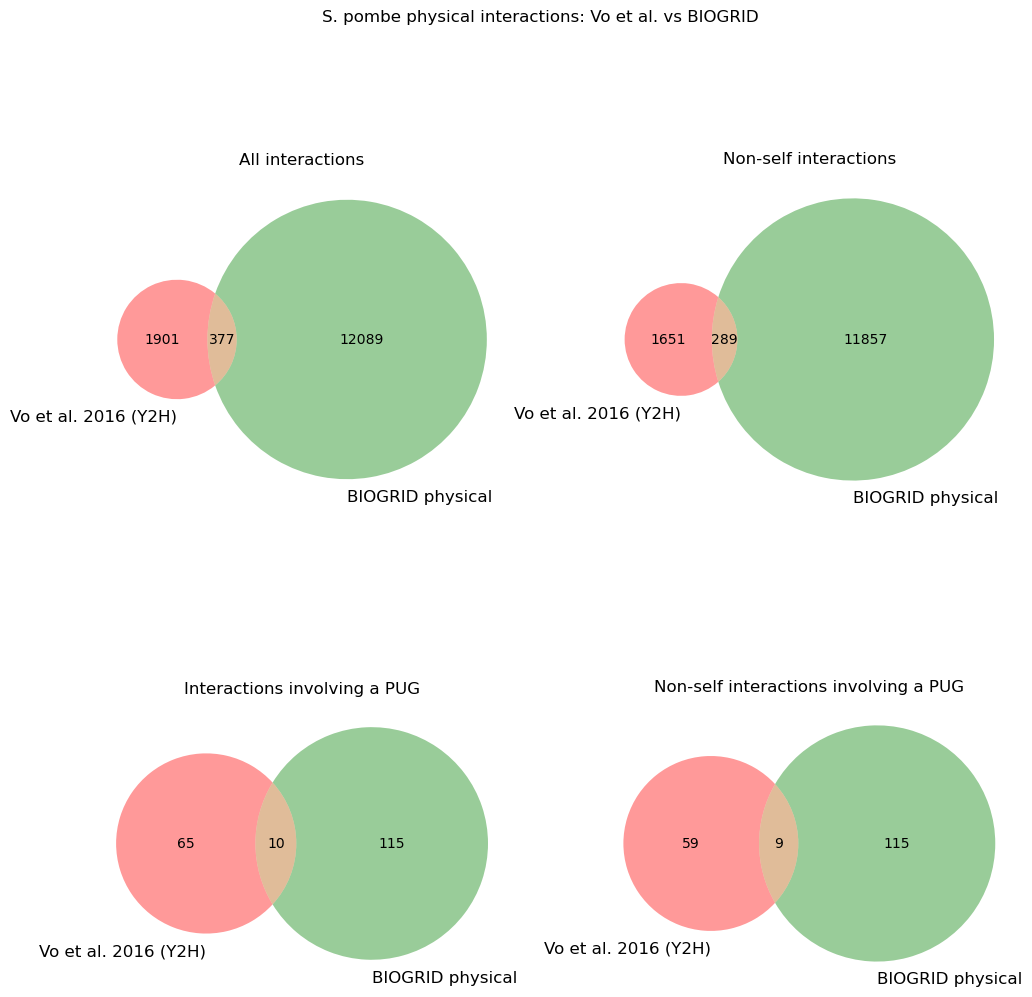

,sp_gene_1,sp_gene_2,vo_et_al_2016,biogrid_physical,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPAC1002.02,SPAC1786.03,False,1,False,False,False,False
1,SPAC1002.02,SPAC18G6.10,False,1,False,False,False,False
2,SPAC1002.02,SPCC737.03c,False,1,False,False,False,False
3,SPAC1002.03c,SPAC14C4.05c,True,0,False,False,False,False
4,SPAC1002.04c,SPAC23G3.09,False,1,False,False,False,False
5,SPAC1002.04c,SPAC631.02,False,1,False,False,False,False
6,SPAC1002.05c,SPAC821.07c,True,0,False,False,False,False
7,SPAC1002.05c,SPBC1718.07c,False,1,False,False,False,False
8,SPAC1002.06c,SPAC6G9.13c,False,7,False,False,False,False
9,SPAC1002.06c,SPBC1778.02,False,5,False,False,False,False


In [ ]:
# One row per unique interaction across both datasets: a boolean for Vo et al.
# (present/absent) and a count for BIOGRID (may be supported by >1 row)
vo_pairs = vo_y2h_df[["sp_gene_1", "sp_gene_2"]].drop_duplicates()
vo_pairs["vo_et_al_2016"] = True

biogrid_counts = (
    biogrid_pombe_physical_filtered_df
    .groupby(["sp_gene_1", "sp_gene_2"])
    .size()
    .reset_index(name="biogrid_physical")
)

pombe_ppi_overlap_df = pd.merge(vo_pairs, biogrid_counts, on=["sp_gene_1", "sp_gene_2"], how="outer")
pombe_ppi_overlap_df["vo_et_al_2016"] = pombe_ppi_overlap_df["vo_et_al_2016"].fillna(False)
pombe_ppi_overlap_df["biogrid_physical"] = pombe_ppi_overlap_df["biogrid_physical"].fillna(0).astype(int)
pombe_ppi_overlap_df = pombe_ppi_overlap_df.sort_values(["sp_gene_1", "sp_gene_2"]).reset_index(drop=True)

# Annotate PUG status of each gene in the pair, to allow filtering below
pombe_ppi_overlap_df = ugt.annotate_unknown_and_pug(pombe_ppi_overlap_df, "sp_gene_1", unknown_df)
pombe_ppi_overlap_df = ugt.annotate_unknown_and_pug(pombe_ppi_overlap_df, "sp_gene_2", unknown_df)

print(pombe_ppi_overlap_df.shape)
pombe_ppi_overlap_df.to_csv(BASE_DIR / "ppis" / "pombe_ppi_overlap_vo_biogrid.csv", index=False)

is_self = pombe_ppi_overlap_df["sp_gene_1"] == pombe_ppi_overlap_df["sp_gene_2"]
involves_pug = (
    pombe_ppi_overlap_df["sp_gene_1_PUG"].fillna(False).astype(bool)
    | pombe_ppi_overlap_df["sp_gene_2_PUG"].fillna(False).astype(bool)
)

def get_venn_sets(mask):
    """Return (vo_set, biogrid_set) of interacting pairs satisfying mask."""
    subset = pombe_ppi_overlap_df.loc[mask]
    vo_set = set(map(tuple, subset.loc[subset["vo_et_al_2016"], ["sp_gene_1", "sp_gene_2"]].values))
    biogrid_set = set(map(tuple, subset.loc[subset["biogrid_physical"] > 0, ["sp_gene_1", "sp_gene_2"]].values))
    return vo_set, biogrid_set

venn_panels = [
    ("All interactions", pd.Series(True, index=pombe_ppi_overlap_df.index)),
    ("Non-self interactions", ~is_self),
    ("Interactions involving a PUG", involves_pug),
    ("Non-self interactions involving a PUG", ~is_self & involves_pug),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, (title, mask) in zip(axes.flat, venn_panels):
    vo_set, biogrid_set = get_venn_sets(mask)
    venn2([vo_set, biogrid_set], set_labels=("Vo et al. 2016 (Y2H)", "BIOGRID physical"), ax=ax)
    ax.set_title(title)

fig.suptitle("S. pombe physical interactions: Vo et al. vs BIOGRID")
plt.show()

pombe_ppi_overlap_df.head(10)

In [ ]:
# Non-self PUG interactions supported by both Vo et al. and BIOGRID
shared_mask = ~is_self & involves_pug & pombe_ppi_overlap_df["vo_et_al_2016"] & (pombe_ppi_overlap_df["biogrid_physical"] > 0)
shared_pug_interactions_df = pombe_ppi_overlap_df.loc[shared_mask, ["sp_gene_1", "sp_gene_2"]].reset_index(drop=True)

shared_pug_interactions_df = ugt.add_gene_name_column(shared_pug_interactions_df, "sp_gene_1")
shared_pug_interactions_df = ugt.add_gene_name_column(shared_pug_interactions_df, "sp_gene_2")

print(shared_pug_interactions_df.shape)
shared_pug_interactions_df

(9, 4)


,sp_gene_1,sp_gene_1_name,sp_gene_2,sp_gene_2_name
0,SPAC12B10.02c,sdg1,SPAC14C4.05c,man1
1,SPAC14C4.05c,man1,SPAC6F12.04,tvp15
2,SPAC17G8.10c,dma1,SPAC6F12.04,tvp15
3,SPAC1B3.08,SPAC1B3.08,SPAC3G6.02,dss1
4,SPAC20H4.03c,tfs1,SPAC27D7.04,omt2
5,SPAC20H4.03c,tfs1,SPAC6F12.04,tvp15
6,SPAC222.11,hem13,SPAC26H5.09c,SPAC26H5.09c
7,SPAC27D7.04,omt2,SPAC29B12.06c,rcd1
8,SPAC27D7.04,omt2,SPCC962.03c,cut15


# Interactions between Orthologs in S. cerevisiae

In [45]:
CEREV_ORTHOLOG_PATH = BASE_DIR / "ppis" / "scer_interactions" / "pombe_cerevisiae_orthologs_20260609.txt"

# ── Build reverse map: cerevisiae gene → S. pombe ortholog(s) ────────────────
# ugt.parse_ortholog_gene_field handles |, +, and (C)/(N) notation
cerev_to_pombe = defaultdict(list)

with open(CEREV_ORTHOLOG_PATH, encoding="utf-8") as fh:
    for line in fh:
        line = line.rstrip("\n")
        if not line.strip():
            continue
        parts = line.split("\t")
        if len(parts) < 2:
            continue
        pombe_gene  = parts[0].strip()   # kept exactly as-is (incl. fusion notation)
        cerev_field = parts[1].strip()

        for cerev_name in ugt.parse_ortholog_gene_field(cerev_field):
            if pombe_gene not in cerev_to_pombe[cerev_name]:
                cerev_to_pombe[cerev_name].append(pombe_gene)

print(f"Unique cerevisiae gene names in reverse map : {len(cerev_to_pombe)}")
print(f"Total (cerevisiae, pombe) pairs             : {sum(len(v) for v in cerev_to_pombe.values())}")

# Preview entries with >1 pombe ortholog
multi_pombe_cerev = {c: ps for c, ps in cerev_to_pombe.items() if len(ps) > 1}
print(f"\nCerevisiae genes with >1 S. pombe ortholog  : {len(multi_pombe_cerev)}")
for cerev, pombes in sorted(multi_pombe_cerev.items())[:10]:
    print(f"  {cerev:15s} → {pombes}")

Unique cerevisiae gene names in reverse map : 4219
Total (cerevisiae, pombe) pairs             : 5289

Cerevisiae genes with >1 S. pombe ortholog  : 706
  YAL005C         → ['SPAC13G7.02c', 'SPCC1739.13']
  YAL019W         → ['SPAC20G8.08c', 'SPAC25A8.01c', 'SPCC1235.05c']
  YAL029C         → ['SPBC2D10.14c', 'SPCC1919.10c']
  YAL034C         → ['SPAC14C4.12c', 'SPCC1682.13']
  YAL049C         → ['SPAC977.15', 'SPBC30D10.14']
  YAL053W         → ['SPAC1F7.03', 'SPCC663.14c']
  YAR071W         → ['SPBC21H7.03c', 'SPBC428.03c', 'SPBP4G3.02']
  YBL003C         → ['SPAC19G12.06c', 'SPCC622.08c']
  YBL024W         → ['SPAC17D4.04', 'SPAC23C4.17']
  YBL027W         → ['SPBC56F2.02', 'SPCC1682.14']


In [46]:
sc_genes_w_pombe_orthologs = len(cerev_to_pombe)
total_verified_orfs = 5757 # from https://www.yeastgenome.org/genomesnapshot as of 20260928

print("total possible non-self interactions between S.cerevisiae genes with S. pombe orthologs : {}".format(sc_genes_w_pombe_orthologs*(sc_genes_w_pombe_orthologs-1)))

print("total possible non-self interactions between S.cerevisiae genes in which only one has an S. pombe orthologs : {}".format(sc_genes_w_pombe_orthologs*(total_verified_orfs-sc_genes_w_pombe_orthologs)))



total possible non-self interactions between S.cerevisiae genes with S. pombe orthologs : 17795742
total possible non-self interactions between S.cerevisiae genes in which only one has an S. pombe orthologs : 6488822


## 3) Lambourne et al. 2026 Yeast 2 Hybrid (S. cerevisiae)

Load the Y2H-union interactions, map each S. cerevisiae ORF to its S. pombe
ortholog(s) (expanding rows for one-to-many mappings), sort each pair
alphabetically, and annotate whether each gene is an unstudied gene / PUG.

In [ ]:
lambourne_raw_df = pd.read_csv(LAMBOURNE_DIR / "Y2H-union.tsv", sep="\t")
print(lambourne_raw_df.shape)
lambourne_raw_df.head(5)


(4556, 8)


,orf_name_a,gene_name_a,orf_name_b,gene_name_b,Uetz-screen,Ito-core,CCSB-YI1,YeRI
0,Q0085,ATP6,YCR106W,RDS1,False,False,True,False
1,R0020C,REP1,YGR048W,UFD1,False,False,False,True
2,YAL005C,SSA1,YBR101C,FES1,False,False,True,False
3,YAL008W,FUN14,YGL029W,CGR1,False,False,False,True
4,YAL012W,CYS3,YAL012W,CYS3,False,False,True,False


In [112]:
# Map each S. cerevisiae ORF interaction to S. pombe ortholog(s), expanding
# rows for one-to-many mappings (rows with no ortholog get NA)
lambourne_mapped_df = ugt.map_interactions_to_ortholog(
    lambourne_raw_df, "orf_name_a", "orf_name_b", cerev_to_pombe
)
print(lambourne_mapped_df.shape)

# orf_name/gene_name are tied to a specific gene of the pair, not the interaction,
# so rename to the _1/_2 slot convention and swap them in tandem with sp_gene_1/2
lambourne_mapped_df = lambourne_mapped_df.rename(columns={
    "orf_name_a": "sc_gene_1", "orf_name_b": "sc_gene_2",
    "gene_name_a": "gene_name_1", "gene_name_b": "gene_name_2",
})

# Sort each pair so sc_gene_1 is alphabetically first, and annotate unknown/PUG status
lambourne_mapped_df = ugt.sort_gene_pair_columns(
    lambourne_mapped_df, "sc_gene_1", "sc_gene_2",
    linked_column_pairs=[("sp_gene_1", "sp_gene_2"), ("gene_name_1", "gene_name_2")],
)
lambourne_mapped_df = ugt.annotate_unknown_and_pug(lambourne_mapped_df, "sp_gene_1", unknown_df)
lambourne_mapped_df = ugt.annotate_unknown_and_pug(lambourne_mapped_df, "sp_gene_2", unknown_df)

# Remove interactions with no S. pombe ortholog for either interactor
lambourne_mapped_df = lambourne_mapped_df.dropna(
    subset=["sp_gene_1", "sp_gene_2"], how="all"
)

lambourne_mapped_df.to_csv(LAMBOURNE_DIR / "Y2H-union_mapped_to_spombe.csv", index=False)

lambourne_mapped_df.head(10)

(6011, 10)


,sp_gene_1,sp_gene_2,sc_gene_1,gene_name_1,sc_gene_2,gene_name_2,Uetz-screen,Ito-core,CCSB-YI1,YeRI,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPMIT.07,<NA>,Q0085,ATP6,YCR106W,RDS1,False,False,True,False,False,False,<NA>,<NA>
1,<NA>,SPBC16A3.09c,R0020C,REP1,YGR048W,UFD1,False,False,False,True,<NA>,<NA>,False,False
2,SPAC13G7.02c,SPBC3B9.01,YAL005C,SSA1,YBR101C,FES1,False,False,True,False,False,False,False,False
3,SPCC1739.13,SPBC3B9.01,YAL005C,SSA1,YBR101C,FES1,False,False,True,False,False,False,False,False
4,SPAC29A4.17c,SPAC1556.05c,YAL008W,FUN14,YGL029W,CGR1,False,False,False,True,False,False,False,False
6,SPAP8A3.09c,<NA>,YAL016W,TPD3,YGR161C,RTS3,False,False,False,True,False,False,<NA>,<NA>
7,SPAP8A3.09c,SPBC11G11.01,YAL016W,TPD3,YIL065C,FIS1,False,False,True,False,False,False,False,False
8,SPAP8A3.09c,SPBC27B12.04c,YAL016W,TPD3,YNL127W,FAR11,True,False,True,False,False,False,False,False
9,SPAC10F6.04,SPAC8F11.02c,YAL020C,ATS1,YBL071W-A,KTI11,False,False,True,True,False,False,False,False
10,SPCC31H12.08c,SPAC664.15,YAL021C,CCR4,YJL112W,MDV1,False,False,True,False,False,False,False,False


## 4) Michaelis et al. 2023 AP/MS (S. cerevisiae)

Load the Yeast Interactome edges, map each S. cerevisiae ORF to its S. pombe
ortholog(s) (expanding rows for one-to-many mappings), sort each pair
alphabetically, and annotate whether each gene is an unstudied gene / PUG.

In [ ]:
michaelis_raw_df = pd.read_csv(MICHAELIS_DIR / "The_Yeast_Interactome_Edges.csv", sep=";")
print(michaelis_raw_df.shape)
michaelis_raw_df.head(5)


(31004, 25)


,name,source,Source Gene names (SGD/UniProt-primary or ordered locus),target,Target Gene names (SGD/UniProt-primary or ordered locus),score_FDR+cor,score_FDR,score_cor,F_FDR_0.05,F_FDR_0.01,...,R_FDR_1e-04,cor_val_[std_dev],cor_val_>=4_[std_dev],cor_val_>=5_[std_dev],Inter-cluster edge,Count of publications,Pubmed Ids,Binary (literature evidence APID),experimentral System,interaction
0,YER136W (interacts with) YNL015W,YER136W,GDI1,YNL015W,PBI2,2,0,2,False,False,...,False,5.789951e+09,True,True,True,0,NaN,NaN,NaN,interacts with
1,YER136W (interacts with) YNL104C,YER136W,GDI1,YNL104C,LEU4,2,0,2,False,False,...,False,5.116362e+09,True,True,True,0,NaN,NaN,NaN,interacts with
2,YER136W (interacts with) YKR066C,YER136W,GDI1,YKR066C,CCP1,2,0,2,False,False,...,False,6.100250e+09,True,True,True,0,NaN,NaN,NaN,interacts with
3,YER136W (interacts with) YLR420W,YER136W,GDI1,YLR420W,URA4,2,0,2,False,False,...,False,6.961443e+09,True,True,True,0,NaN,NaN,NaN,interacts with
4,YER136W (interacts with) YKL024C,YER136W,GDI1,YKL024C,URA6,2,0,2,False,False,...,False,7.837827e+09,True,True,True,0,NaN,NaN,NaN,interacts with


In [113]:
# Map each S. cerevisiae ORF interaction to S. pombe ortholog(s), expanding
# rows for one-to-many mappings (rows with no ortholog get NA)
michaelis_mapped_df = ugt.map_interactions_to_ortholog(
    michaelis_raw_df, "source", "target", cerev_to_pombe
)
print(michaelis_mapped_df.shape)

# source/target and their gene name columns are tied to a specific gene of the
# pair, not the interaction, so rename to the _1/_2 slot convention and swap
# them in tandem with sp_gene_1/2
michaelis_mapped_df = michaelis_mapped_df.rename(columns={
    "source": "sc_gene_1", "target": "sc_gene_2",
    "Source Gene names (SGD/UniProt-primary or ordered locus)": "gene_name_1",
    "Target Gene names  (SGD/UniProt-primary or ordered locus)": "gene_name_2",
})

# Sort each pair so sp_gene_1 is alphabetically first, and annotate unknown/PUG status
michaelis_mapped_df = ugt.sort_gene_pair_columns(
    michaelis_mapped_df, "sc_gene_1", "sc_gene_2",
    linked_column_pairs=[("sp_gene_1", "sp_gene_2"), ("gene_name_1", "gene_name_2")],
)

# Remove interactions with no S. pombe ortholog for either interactor
michaelis_mapped_df = michaelis_mapped_df.dropna(
    subset=["sp_gene_1", "sp_gene_2"], how="all"
)

michaelis_mapped_df = ugt.annotate_unknown_and_pug(michaelis_mapped_df, "sp_gene_1", unknown_df)
michaelis_mapped_df = ugt.annotate_unknown_and_pug(michaelis_mapped_df, "sp_gene_2", unknown_df)



michaelis_mapped_df.to_csv(MICHAELIS_DIR / "Yeast_Interactome_Edges_mapped_to_spombe.csv", index=False)

michaelis_mapped_df.head(10)

(48008, 27)


,sp_gene_1,sp_gene_2,name,sc_gene_1,gene_name_1,sc_gene_2,gene_name_2,score_FDR+cor,score_FDR,score_cor,...,Inter-cluster edge,Count of publications,Pubmed Ids,Binary (literature evidence APID),experimentral System,interaction,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPAC22H10.12c,SPCC338.12,YER136W (interacts with) YNL015W,YER136W,GDI1,YNL015W,PBI2,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
1,SPAC22H10.12c,SPBC3E7.16c,YER136W (interacts with) YNL104C,YER136W,GDI1,YNL104C,LEU4,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
2,SPAC22H10.12c,<NA>,YER136W (interacts with) YKR066C,YER136W,GDI1,YKR066C,CCP1,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,<NA>,<NA>
3,SPAC22H10.12c,SPAC16.03c,YER136W (interacts with) YLR420W,YER136W,GDI1,YLR420W,URA4,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
4,SPAC22H10.12c,SPCC1795.05c,YER136W (interacts with) YKL024C,YER136W,GDI1,YKL024C,URA6,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
5,SPAC22H10.12c,SPAC4C5.01,YER136W (interacts with) YKL033W-A,YER136W,GDI1,YKL033W-A,YKL033W-A,2,0,2,...,False,0,NaN,NaN,NaN,interacts with,False,False,False,False
6,SPAC22H10.12c,SPCC1020.07,YER136W (interacts with) YKL033W-A,YER136W,GDI1,YKL033W-A,YKL033W-A,2,0,2,...,False,0,NaN,NaN,NaN,interacts with,False,False,False,False
7,SPAC22H10.12c,SPBC21C3.19,YER136W (interacts with) YHR087W,YER136W,GDI1,YHR087W,RTC3,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
8,SPAC22H10.12c,SPBC1347.04,YER136W (interacts with) YJL054W,YER136W,GDI1,YJL054W,TIM54,2,0,2,...,True,0,NaN,NaN,NaN,interacts with,False,False,False,False
9,SPAC22H10.12c,SPAC6F6.15,YER136W (interacts with) YOR089C,YER136W,GDI1,YOR089C,VPS21,8,8,0,...,False,8,"PUBMED:11805837, PUBMED:11116150, PUBMED:10329...",True,"Affinity Capture-MS, Affinity Capture-Western,...",interacts with,False,False,False,False


## 5) BIOGRID Physical Interactions (S. cerevisiae orthologs)

Load the BIOGRID S. cerevisiae tab3 file, keep only physical interactions,
remove interactions already covered by Lambourne et al. (Yu et al. 2008,
Uetz et al. 2000, Ito et al. 2001) and Michaelis et al. 2023, map each
S. cerevisiae ORF to its S. pombe ortholog(s) (expanding rows for one-to-many
mappings), sort each pair alphabetically, and annotate whether each gene is
an unstudied gene / PUG.

In [43]:
biogrid_cerevisiae_physical_df = ugt.load_biogrid_physical_data(
    "Saccharomyces_cerevisiae_S288c", BIOGRID_DIR, col_a="sc_gene_1", col_b="sc_gene_2"
)
print(biogrid_cerevisiae_physical_df.shape)

# Keep only interactions between two S. cerevisiae proteins (exclude cross-species entries)
biogrid_cerevisiae_physical_df = biogrid_cerevisiae_physical_df[
    (biogrid_cerevisiae_physical_df["Organism Name Interactor A"] == "Saccharomyces cerevisiae (S288c)")
    & (biogrid_cerevisiae_physical_df["Organism Name Interactor B"] == "Saccharomyces cerevisiae (S288c)")
].copy()
print(biogrid_cerevisiae_physical_df.shape)

biogrid_cerevisiae_physical_df.to_csv(BIOGRID_DIR / "biogrid_cerevisiae_physical.csv", index=False)

biogrid_cerevisiae_physical_df.head(10)

(286660, 37)
(282877, 37)


,sc_gene_1,sc_gene_2,BioGRID Interaction ID,Entrez Gene Interactor A,Entrez Gene Interactor B,BioGRID ID Interactor A,BioGRID ID Interactor B,Official Symbol Interactor A,Official Symbol Interactor B,Synonyms Interactor A,...,TREMBL Accessions Interactor B,REFSEQ Accessions Interactor B,Ontology Term IDs,Ontology Term Names,Ontology Term Categories,Ontology Term Qualifier IDs,Ontology Term Qualifier Names,Ontology Term Types,Organism Name Interactor A,Organism Name Interactor B
0,YLR418C,YOL145C,68770,851136,854020,31676,34272,CDC73,CTR9,L000002792,...,-,NP_014496,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
1,YOL145C,YLR418C,68771,854020,851136,34272,31676,CTR9,CDC73,CDP1|L000003477,...,-,NP_013522,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
2,YLR418C,YOR123C,68774,851136,854290,31676,34518,CDC73,LEO1,L000002792,...,-,NP_014766,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
3,YOR123C,YLR418C,68775,854290,851136,34518,31676,LEO1,CDC73,L000000936,...,-,NP_013522,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
4,YLR418C,YBR279W,68778,851136,852582,31676,32973,CDC73,PAF1,L000002792,...,-,NP_009838,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
5,YBR279W,YLR418C,68779,852582,851136,32973,31676,PAF1,CDC73,L000002621,...,-,NP_013522,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
6,YLR418C,YML069W,68782,851136,854933,31676,35097,CDC73,POB3,L000002792,...,-,NP_013642,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
7,YML069W,YLR418C,68783,854933,851136,35097,31676,POB3,CDC73,FACT complex subunit POB3|L000003326,...,-,NP_013522,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
8,YLR418C,YGL244W,68786,851136,852607,31676,32996,CDC73,RTF1,L000002792,...,-,NP_011270,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)
9,YGL244W,YLR418C,68787,852607,851136,32996,31676,RTF1,CDC73,CSL3|L000001782,...,-,NP_013522,-,-,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c)


In [49]:
# Remove interactions already covered by Lambourne et al. (Y2H-union: Yu 2008,
# Uetz 2000, Ito 2001) and Michaelis et al. 2023 (redundant sources)
excluded_pubmed_sources = {
    "PUBMED:37968396",  # Michaelis et al. 2023
    "PUBMED:18719252",  # Yu et al. 2008
    "PUBMED:10688190",  # Uetz et al. 2000
    "PUBMED:11283351",  # Ito et al. 2001
}
biogrid_cerevisiae_physical_filtered_df = biogrid_cerevisiae_physical_df[
    ~biogrid_cerevisiae_physical_df["Publication Source"].isin(excluded_pubmed_sources)
].copy()
print(biogrid_cerevisiae_physical_filtered_df.shape)

# Official Symbol columns are tied to a specific gene of the pair, not the interaction
biogrid_cerevisiae_physical_filtered_df = biogrid_cerevisiae_physical_filtered_df.rename(columns={
    "Official Symbol Interactor A": "sc_name_1", "Official Symbol Interactor B": "sc_name_2",
})

# Map each S. cerevisiae ORF interaction to S. pombe ortholog(s), expanding
# rows for one-to-many mappings (rows with no ortholog get NA)
biogrid_cerevisiae_physical_filtered_df = ugt.map_interactions_to_ortholog(
    biogrid_cerevisiae_physical_filtered_df, "sc_gene_1", "sc_gene_2", cerev_to_pombe
)
print(biogrid_cerevisiae_physical_filtered_df.shape)

# Sort each pair so sc_gene_1 is alphabetically first, and annotate unknown/PUG status
biogrid_cerevisiae_physical_filtered_df = ugt.sort_gene_pair_columns(
    biogrid_cerevisiae_physical_filtered_df, "sc_gene_1", "sc_gene_2",
    linked_column_pairs=[("sp_gene_1", "sp_gene_2"), ("sc_name_1", "sc_name_2")],
)

# Remove interactions with no S. pombe ortholog for either interactor
biogrid_cerevisiae_physical_filtered_df = biogrid_cerevisiae_physical_filtered_df.dropna(
    subset=["sp_gene_1", "sp_gene_2"], how="all"
)
print(biogrid_cerevisiae_physical_filtered_df.shape)

biogrid_cerevisiae_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_cerevisiae_physical_filtered_df, "sp_gene_1", unknown_df
)
biogrid_cerevisiae_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_cerevisiae_physical_filtered_df, "sp_gene_2", unknown_df
)

biogrid_cerevisiae_physical_filtered_df.to_csv(BIOGRID_DIR / "biogrid_cerevisiae_physical_filtered.csv", index=False)

biogrid_cerevisiae_physical_filtered_df.head(10)

(248329, 37)
(360312, 39)
(356233, 39)


,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,BioGRID Interaction ID,Entrez Gene Interactor A,Entrez Gene Interactor B,BioGRID ID Interactor A,BioGRID ID Interactor B,sc_name_1,...,Ontology Term Categories,Ontology Term Qualifier IDs,Ontology Term Qualifier Names,Ontology Term Types,Organism Name Interactor A,Organism Name Interactor B,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPBC17G9.02c,SPAC27D7.14c,YLR418C,YOL145C,68770,851136,854020,31676,34272,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
1,SPBC17G9.02c,SPAC27D7.14c,YLR418C,YOL145C,68771,854020,851136,34272,31676,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
2,SPBC17G9.02c,SPBC13E7.08c,YLR418C,YOR123C,68774,851136,854290,31676,34518,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
3,SPBC17G9.02c,SPBC13E7.08c,YLR418C,YOR123C,68775,854290,851136,34518,31676,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
4,SPAC664.03,SPBC17G9.02c,YBR279W,YLR418C,68778,851136,852582,31676,32973,PAF1,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
5,SPAC664.03,SPBC17G9.02c,YBR279W,YLR418C,68779,852582,851136,32973,31676,PAF1,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
6,SPBC17G9.02c,SPBC609.05,YLR418C,YML069W,68782,851136,854933,31676,35097,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
7,SPBC17G9.02c,SPBC609.05,YLR418C,YML069W,68783,854933,851136,35097,31676,CDC73,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
8,SPBC651.09c,SPBC17G9.02c,YGL244W,YLR418C,68786,851136,852607,31676,32996,RTF1,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False
9,SPBC651.09c,SPBC17G9.02c,YGL244W,YLR418C,68787,852607,851136,32996,31676,RTF1,...,-,-,-,-,Saccharomyces cerevisiae (S288c),Saccharomyces cerevisiae (S288c),False,False,False,False


## Combine S. cerevisiae ortholog-derived interaction data

Standardize `lambourne_mapped_df`, `michaelis_mapped_df`, and
`biogrid_cerevisiae_physical_filtered_df` down to a common set of columns
(sp_gene_1/2, sc_gene_1/2, and a per-dataset interaction indicator), then
merge them into a single combined table.

In [50]:
# Lambourne: interaction count = number of screens (of 4) that reported the pair
lambourne_summary_df = lambourne_mapped_df.rename(columns={
    "orf_name_1": "sc_gene_1", "orf_name_2": "sc_gene_2",
})
lambourne_summary_df["lambourne_interactions"] = (
    lambourne_summary_df[["Uetz-screen", "Ito-core", "CCSB-YI1", "YeRI"]].sum(axis=1)
)
lambourne_summary_df = lambourne_summary_df[
    ["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2", "lambourne_interactions"]
]
print(lambourne_summary_df.shape)

# Michaelis: every row is a reported interaction, so the indicator is always True
michaelis_summary_df = michaelis_mapped_df.rename(columns={
    "orf_name_1": "sc_gene_1", "orf_name_2": "sc_gene_2",
})
michaelis_summary_df["michaelis_interaction"] = True
michaelis_summary_df = michaelis_summary_df[
    ["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2", "michaelis_interaction"]
]
print(michaelis_summary_df.shape)

# BIOGRID: count distinct supporting publications per S. cerevisiae gene pair.
# Paralog expansion can create multiple rows for the same (sc pair, publication),
# so collapse those first; then group by sc_gene_1/sc_gene_2 (not sp_gene_1/2,
# since NA sp_gene values would otherwise break/mis-group the aggregation).
biogrid_cerev_prep_df = biogrid_cerevisiae_physical_filtered_df[
    ["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2", "Publication Source"]
]

biogrid_cerev_pub_dedup_df = biogrid_cerev_prep_df.drop_duplicates(
    subset=["sc_gene_1", "sc_gene_2", "Publication Source"]
)

biogrid_cerev_counts = (
    biogrid_cerev_pub_dedup_df
    .groupby(["sc_gene_1", "sc_gene_2"])
    .size()
    .reset_index(name="biogrid_physical")
)

biogrid_cerev_summary_df = (
    biogrid_cerev_prep_df[["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2"]]
    .drop_duplicates()
    .merge(biogrid_cerev_counts, on=["sc_gene_1", "sc_gene_2"], how="left")
)
print(biogrid_cerev_summary_df.shape)

(5725, 5)
(47602, 5)
(257106, 5)


In [51]:
# Outer-merge all three standardized datasets on the (sp_gene, sc_gene) pair
cerev_ppi_overlap_df = lambourne_summary_df.merge(
    michaelis_summary_df, on=["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2"], how="outer"
).merge(
    biogrid_cerev_summary_df, on=["sp_gene_1", "sp_gene_2", "sc_gene_1", "sc_gene_2"], how="outer"
)

cerev_ppi_overlap_df["lambourne_interactions"] = cerev_ppi_overlap_df["lambourne_interactions"].fillna(0).astype(int)
cerev_ppi_overlap_df["michaelis_interaction"] = cerev_ppi_overlap_df["michaelis_interaction"].fillna(False)
cerev_ppi_overlap_df["biogrid_physical"] = cerev_ppi_overlap_df["biogrid_physical"].fillna(0).astype(int)

print(cerev_ppi_overlap_df.shape)
cerev_ppi_overlap_df.to_csv(BASE_DIR / "ppis" / "cerev_ppi_overlap_lambourne_michaelis_biogrid.csv", index=False)

cerev_ppi_overlap_df.head(10)

(292917, 7)


,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,lambourne_interactions,michaelis_interaction,biogrid_physical
0,SPMIT.07,NaN,Q0085,YCR106W,1,False,0
1,NaN,SPBC16A3.09c,R0020C,YGR048W,1,False,0
2,SPAC13G7.02c,SPBC3B9.01,YAL005C,YBR101C,1,True,8
3,SPCC1739.13,SPBC3B9.01,YAL005C,YBR101C,1,True,8
4,SPAC29A4.17c,SPAC1556.05c,YAL008W,YGL029W,1,False,0
5,SPAP8A3.09c,NaN,YAL016W,YGR161C,1,False,4
6,SPAP8A3.09c,SPBC11G11.01,YAL016W,YIL065C,1,False,0
7,SPAP8A3.09c,SPBC27B12.04c,YAL016W,YNL127W,2,True,2
8,SPAC10F6.04,SPAC8F11.02c,YAL020C,YBL071W-A,2,True,6
9,SPCC31H12.08c,SPAC664.15,YAL021C,YJL112W,1,False,1


In [52]:
# Sort each pair so sp_gene_1 is alphabetically first, keeping sc_gene_1/2 linked,
# and annotate unknown/PUG status
cerev_ppi_overlap_df = ugt.sort_gene_pair_columns(
    cerev_ppi_overlap_df, "sp_gene_1", "sp_gene_2",
    linked_column_pairs=[("sc_gene_1", "sc_gene_2")],
)
cerev_ppi_overlap_df = ugt.annotate_unknown_and_pug(cerev_ppi_overlap_df, "sp_gene_1", unknown_df)
cerev_ppi_overlap_df = ugt.annotate_unknown_and_pug(cerev_ppi_overlap_df, "sp_gene_2", unknown_df)

print(cerev_ppi_overlap_df.shape)
cerev_ppi_overlap_df.head(10)

(292917, 11)


,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,lambourne_interactions,michaelis_interaction,biogrid_physical,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPMIT.07,NaN,Q0085,YCR106W,1,False,0,False,False,<NA>,<NA>
1,SPBC16A3.09c,NaN,YGR048W,R0020C,1,False,0,False,False,<NA>,<NA>
2,SPAC13G7.02c,SPBC3B9.01,YAL005C,YBR101C,1,True,8,False,False,False,False
3,SPBC3B9.01,SPCC1739.13,YBR101C,YAL005C,1,True,8,False,False,False,False
4,SPAC1556.05c,SPAC29A4.17c,YGL029W,YAL008W,1,False,0,False,False,False,False
5,SPAP8A3.09c,NaN,YAL016W,YGR161C,1,False,4,False,False,<NA>,<NA>
6,SPAP8A3.09c,SPBC11G11.01,YAL016W,YIL065C,1,False,0,False,False,False,False
7,SPAP8A3.09c,SPBC27B12.04c,YAL016W,YNL127W,2,True,2,False,False,False,False
8,SPAC10F6.04,SPAC8F11.02c,YAL020C,YBL071W-A,2,True,6,False,False,False,False
9,SPAC664.15,SPCC31H12.08c,YJL112W,YAL021C,1,False,1,False,False,False,False


In [54]:
# Total interactions between genes with two S. pombe orthologs (self/non-self),
# and interactions where only one gene has a S. pombe ortholog
both_orthologs = cerev_ppi_overlap_df["sp_gene_1"].notna() & cerev_ppi_overlap_df["sp_gene_2"].notna()
single_ortholog = cerev_ppi_overlap_df["sp_gene_1"].notna() ^ cerev_ppi_overlap_df["sp_gene_2"].notna()
is_self = cerev_ppi_overlap_df.loc[both_orthologs, "sp_gene_1"] == cerev_ppi_overlap_df.loc[both_orthologs, "sp_gene_2"]

cerev_ppi_summary_df = pd.DataFrame([{
    "total_interactions": len(cerev_ppi_overlap_df),
    "both_orthologs_total": int(both_orthologs.sum()),
    "both_orthologs_self": int(is_self.sum()),
    "both_orthologs_non_self": int(both_orthologs.sum()) - int(is_self.sum()),
    "single_ortholog": int(single_ortholog.sum()),
}])

cerev_ppi_summary_df

,total_interactions,both_orthologs_total,both_orthologs_self,both_orthologs_non_self,single_ortholog
0,292917,242627,2435,240192,50290


# Interactions involving orthologs in Human

In [16]:
# Construct a dictionary to map a human gene name to its ortholog(s) in S. pombe.
HUMAN_ORTHOLOG_PATH = BASE_DIR / "ppis" / "human_interactions" / "pombe_human_orthologs_20260605.txt"

human_to_pombe = defaultdict(list)

with open(HUMAN_ORTHOLOG_PATH, encoding="utf-8") as fh:
    for line in fh:
        line = line.rstrip("\n")
        if not line.strip():
            continue
        parts = line.split("\t")
        if len(parts) < 2:
            continue
        pombe_gene = parts[0].strip()
        human_field = parts[1].strip()

        for human_name in ugt.parse_ortholog_gene_field(human_field):
            if pombe_gene not in human_to_pombe[human_name]:
                human_to_pombe[human_name].append(pombe_gene)

print(f"Unique human gene names in reverse map : {len(human_to_pombe)}")
print(f"Total (human, pombe) ortholog pairs     : {sum(len(v) for v in human_to_pombe.values())}")

# Preview human genes with multiple S. pombe orthologs
multi_pombe_human = {human: pombes for human, pombes in human_to_pombe.items() if len(pombes) > 1}
print(f"\nHuman genes with >1 S. pombe ortholog  : {len(multi_pombe_human)}")
for human, pombes in sorted(multi_pombe_human.items())[:10]:
    print(f"  {human:15s} -> {pombes}")

Unique human gene names in reverse map : 4529
Total (human, pombe) ortholog pairs     : 5660

Human genes with >1 S. pombe ortholog  : 792
  AADAT           -> ['SPAC56E4.03', 'SPBC1773.13', 'SPCC569.07']
  AAK1            -> ['SPBC557.04', 'SPBC6B1.02', 'SPCP1E11.02']
  AASS            -> ['SPAC227.18', 'SPBC3B8.03']
  ABCC1           -> ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC2           -> ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC3           -> ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCC6           -> ['SPAC30.04c', 'SPAC3F10.11c', 'SPAC9E9.12c', 'SPBC359.05']
  ABCG1           -> ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG2           -> ['SPAPB24D3.09c', 'SPCC18B5.01c']
  ABCG4           -> ['SPAPB24D3.09c', 'SPCC18B5.01c']


In [24]:
# Some Y2H datasets use ENSEMBL gene identifiers, so map those IDs to S. pombe ortholog(s).
HUMAN_BIOMART_PATH = BASE_DIR / "ppis" / "human_interactions" / "ensembl_biomart_export_20260605.txt"

human_biomart_df = pd.read_csv(
    HUMAN_BIOMART_PATH,
    sep="\t",
    usecols=["Gene stable ID", "Gene name"],
    dtype="string",
)
for column in ["Gene stable ID", "Gene name"]:
    human_biomart_df[column] = human_biomart_df[column].str.strip().replace("", pd.NA)

ensembl_ids = set(human_biomart_df["Gene stable ID"].dropna())
ensembl_ids_with_names = set(
    human_biomart_df.dropna(subset=["Gene stable ID", "Gene name"])["Gene stable ID"]
)
missing_ensembl_gene_name_count = len(ensembl_ids - ensembl_ids_with_names)

biomart_gene_names = set(human_biomart_df["Gene name"].dropna())
human_names_without_ensembl_id = set(human_to_pombe) - biomart_gene_names

human_to_pombe_ensembl = defaultdict(list)
biomart_name_id_pairs = human_biomart_df.dropna(
    subset=["Gene stable ID", "Gene name"]
).drop_duplicates(subset=["Gene stable ID", "Gene name"])
for ensembl_id, human_name in biomart_name_id_pairs.itertuples(index=False, name=None):
    for pombe_gene in human_to_pombe.get(human_name, []):
        if pombe_gene not in human_to_pombe_ensembl[ensembl_id]:
            human_to_pombe_ensembl[ensembl_id].append(pombe_gene)

print(f"ENSEMBL IDs missing a gene name in BioMart : {missing_ensembl_gene_name_count}")
print(f"Human ortholog-map names without ENSEMBL ID : {len(human_names_without_ensembl_id)}")
print(f"ENSEMBL IDs mapped to S. pombe orthologs    : {len(human_to_pombe_ensembl)}")
print(f"Total (ENSEMBL ID, pombe) ortholog pairs    : {sum(len(v) for v in human_to_pombe_ensembl.values())}")

ENSEMBL IDs missing a gene name in BioMart : 873
Human ortholog-map names without ENSEMBL ID : 28
ENSEMBL IDs mapped to S. pombe orthologs    : 5013
Total (ENSEMBL ID, pombe) ortholog pairs    : 6234


In [ ]:
# UNIPROT Id Mapping. 
# Some of the datasets (for example the simulated protein protein interactions from Zhang et al.) use uniprot IDs instead of gene symbols.  Therefore we need a mapping from uniprot IDs to pombe ortholog.  

# We do this in two ways and compare it to the mapping between human gene names and pombe orthologs from pombase.  

#First we map the UniProt IDs from the Zhang dataset to gene names using the Name1/Name2 columns provided in the file.

#Secondly, we map the UniProt IDs from the Zhang dataset to gene names using the ENSEMBL BioMart flat file.

ZHANG_PATH = ZHANG_DIR / "final_predictions" / "final_predictions_80.tsv"

# The Zhang file starts with a block of '#' comment lines before the header row.
with open(ZHANG_PATH, encoding="utf-8") as fh:
    n_comment_lines = 0
    for line in fh:
        if not line.startswith("#"):
            break
        n_comment_lines += 1

zhang_df = pd.read_csv(
    ZHANG_PATH,
    sep="\t",
    skiprows=n_comment_lines,
    usecols=["Protein1", "Protein2", "Name1", "Name2"],
    dtype="string",
)
zhang_uniprot_ids = set(zhang_df["Protein1"].dropna().str.strip()) | set(zhang_df["Protein2"].dropna().str.strip())


# Map UniProt ID -> Gene Name using the Name1/Name2 columns that ship with the Zhang file.
zhang_id_name_df = pd.concat([
    zhang_df[["Protein1", "Name1"]].set_axis(["Uniprot ID", "Gene Name"], axis=1),
    zhang_df[["Protein2", "Name2"]].set_axis(["Uniprot ID", "Gene Name"], axis=1),
]).apply(lambda s: s.str.strip()).replace("", pd.NA)

zhang_named_df = zhang_id_name_df.dropna().drop_duplicates()
n_ids_with_conflicting_names = int((zhang_named_df.groupby("Uniprot ID")["Gene Name"].nunique() > 1).sum())

# Keep the first name seen for each ID; IDs that never have a name get "NONE".
zhang_name_map = {uniprot_id: "NONE" for uniprot_id in zhang_uniprot_ids}
zhang_name_map.update(
    zhang_named_df.drop_duplicates(subset="Uniprot ID").set_index("Uniprot ID")["Gene Name"].to_dict()
)

n_zhang_ids_without_name = sum(name == "NONE" for name in zhang_name_map.values())
print()
print(f"Zhang IDs in Name1/Name2 map                : {len(zhang_name_map)}")
print(f"Zhang IDs without a name (NONE)             : {n_zhang_ids_without_name}")
print(f"Zhang IDs with >1 distinct name             : {n_ids_with_conflicting_names}")



# Mapping using the ENSEMBL BioMart flat file.  To determine which column in the file corresponds to the correct Uniprot ID we will check the overlap between the different columns and the uniprot IDs from the Zhang dataset. 


# Candidate UniProt ID columns in BioMart
biomart_uniprot_df = pd.read_csv(
    HUMAN_BIOMART_PATH,
    sep="\t",
    usecols=["UniProtKB/Swiss-Prot ID", "UniProtKB/TrEMBL ID"],
    dtype="string",
)
swissprot_ids = set(biomart_uniprot_df["UniProtKB/Swiss-Prot ID"].dropna().str.strip()) - {""}
trembl_ids = set(biomart_uniprot_df["UniProtKB/TrEMBL ID"].dropna().str.strip()) - {""}

in_swissprot = zhang_uniprot_ids & swissprot_ids
in_trembl = zhang_uniprot_ids & trembl_ids
only_swissprot = in_swissprot - trembl_ids
only_trembl = in_trembl - swissprot_ids
in_both = in_swissprot & in_trembl
in_neither = zhang_uniprot_ids - swissprot_ids - trembl_ids

print(f"Zhang interactions                          : {len(zhang_df)}")
print(f"Unique UniProt IDs in Zhang                 : {len(zhang_uniprot_ids)}")
print(f"Unique IDs in BioMart Swiss-Prot / TrEMBL   : {len(swissprot_ids)} / {len(trembl_ids)}")
print()
print(f"Zhang IDs found in Swiss-Prot column        : {len(in_swissprot)}")
print(f"Zhang IDs found in TrEMBL column            : {len(in_trembl)}")
print(f"Zhang IDs found only in Swiss-Prot          : {len(only_swissprot)}")
print(f"Zhang IDs found only in TrEMBL              : {len(only_trembl)}")
print(f"Zhang IDs found in both columns             : {len(in_both)}")
print(f"Zhang IDs missing from Swiss-Prot column    : {len(zhang_uniprot_ids - swissprot_ids)}")
print(f"Zhang IDs missing from TrEMBL column        : {len(zhang_uniprot_ids - trembl_ids)}")
print(f"Zhang IDs missing from both columns         : {len(in_neither)}")


# Tailor the BioMart dataset to the Zhang dataset
zhang_uniprot_map_biomart_df = ugt.uniprot_biomart_dataset_tailoring(
    biomart_path=HUMAN_BIOMART_PATH,
    dataset_path=ZHANG_PATH,
    dataset_name="zhang",
    output_dir=BASE_DIR / "ppis" / "human_interactions" / "zhang",
)
zhang_uniprot_map_biomart_df.groupby("Source").size()



# Zhang IDs present in a BioMart UniProt column but with no gene name on any of their rows.
biomart_check_df = pd.read_csv(
    HUMAN_BIOMART_PATH, sep="\t", dtype="string",
    usecols=["Gene name", "UniProtKB/Swiss-Prot ID", "UniProtKB/TrEMBL ID"],
)
biomart_check_df = biomart_check_df.apply(lambda s: s.str.strip()).replace("", pd.NA)

nameless_rows = []
for column in ["UniProtKB/Swiss-Prot ID", "UniProtKB/TrEMBL ID"]:
    rows = biomart_check_df.dropna(subset=[column])
    rows = rows[rows[column].isin(zhang_uniprot_ids)]
    named_ids = set(rows.dropna(subset=["Gene name"])[column])
    for uniprot_id in sorted(set(rows[column]) - named_ids):
        nameless_rows.append({"Uniprot ID": uniprot_id, "BioMart column": column})

nameless_biomart_df = pd.DataFrame(nameless_rows)
print(nameless_biomart_df["BioMart column"].value_counts())
nameless_biomart_df


# Merge the Zhang-supplied names with the BioMart-derived names, one row per UniProt ID.
zhang_names_merged_df = (
    zhang_named_df.drop_duplicates(subset="Uniprot ID")
    .rename(columns={"Gene Name": "Gene Name Zhang"})
    .merge(
        zhang_uniprot_map_biomart_df.reset_index().rename(
            columns={"Gene Name": "Gene Name Biomart", "Source": "Source Biomart"}
        ),
        on="Uniprot ID",
        how="outer",
    )
)
zhang_names_merged_df["Gene Name Zhang"] = zhang_names_merged_df["Gene Name Zhang"].fillna("NONE")
zhang_names_merged_df["Gene Name Biomart"] = zhang_names_merged_df["Gene Name Biomart"].fillna("NONE")

zhang_none = zhang_names_merged_df["Gene Name Zhang"] == "NONE"
biomart_none = zhang_names_merged_df["Gene Name Biomart"] == "NONE"
names_identical = zhang_names_merged_df["Gene Name Zhang"] == zhang_names_merged_df["Gene Name Biomart"]

print()
print(f"IDs in merged table                         : {len(zhang_names_merged_df)}")
print(f"Names identical (both non-NONE)             : {int((names_identical & ~zhang_none).sum())}")
print(f"NONE in both                                : {int((zhang_none & biomart_none).sum())}")
print(f"NONE in Zhang only                          : {int((zhang_none & ~biomart_none).sum())}")
print(f"NONE in Biomart only                        : {int((~zhang_none & biomart_none).sum())}")
print(f"Both named but different                    : {int((~zhang_none & ~biomart_none & ~names_identical).sum())}")

# Overlap with the human gene names that have a pombe ortholog
ortholog_gene_names = set(human_to_pombe)
for label, column in [("Zhang", "Gene Name Zhang"), ("Biomart", "Gene Name Biomart")]:
    is_ortholog_name = zhang_names_merged_df[column].isin(ortholog_gene_names)
    print(f"{label:8s} IDs with name in human_to_pombe    : {int(is_ortholog_name.sum())}"
          f" ({zhang_names_merged_df.loc[is_ortholog_name, column].nunique()} unique names)")


# Flag which names exist in the pombe ortholog mapping and whether the two sources agree.
for label in ["Zhang", "Biomart"]:
    zhang_names_merged_df[f"Name in Pombe Mapping {label}"] = (
        zhang_names_merged_df[f"Gene Name {label}"].isin(ortholog_gene_names)
    )
zhang_names_merged_df["Zhang Biomart Match"] = (
    zhang_names_merged_df["Gene Name Zhang"] == zhang_names_merged_df["Gene Name Biomart"]
)

name_match = zhang_names_merged_df["Zhang Biomart Match"]
in_pombe_zhang = zhang_names_merged_df["Name in Pombe Mapping Zhang"]
in_pombe_biomart = zhang_names_merged_df["Name in Pombe Mapping Biomart"]

# Different names that both map to pombe are fine when they map to the same set of pombe genes
# (several gene names sharing one protein); otherwise it is an error.
different_names_both_mapped = ~name_match & in_pombe_zhang & in_pombe_biomart
same_pombe_set = pd.Series(
    [
        bool(both_mapped) and set(human_to_pombe[zhang_name]) == set(human_to_pombe[biomart_name])
        for both_mapped, zhang_name, biomart_name in zip(
            different_names_both_mapped,
            zhang_names_merged_df["Gene Name Zhang"],
            zhang_names_merged_df["Gene Name Biomart"],
        )
    ],
    index=zhang_names_merged_df.index,
)

# Names match but the pombe flags disagree. A matched name absent from the pombe mapping is not an error; it falls to NONE.
inconsistent = (different_names_both_mapped & ~same_pombe_set) | (name_match & (in_pombe_zhang != in_pombe_biomart))
if inconsistent.any():
    print(zhang_names_merged_df[inconsistent].to_string())
    raise ValueError(f"{int(inconsistent.sum())} rows have an inconsistent name/pombe-mapping combination (printed above)")

use_zhang = in_pombe_zhang & (name_match | ~in_pombe_biomart | same_pombe_set)
use_biomart = ~in_pombe_zhang & in_pombe_biomart

zhang_names_merged_df["Gene Name Mapped"] = "NONE"
zhang_names_merged_df.loc[use_zhang, "Gene Name Mapped"] = zhang_names_merged_df.loc[use_zhang, "Gene Name Zhang"]
zhang_names_merged_df.loc[use_biomart, "Gene Name Mapped"] = zhang_names_merged_df.loc[use_biomart, "Gene Name Biomart"]

print()
print(f"Zhang/Biomart names match                   : {int(name_match.sum())}")
print(f"Different names, same pombe genes (Zhang)   : {int(same_pombe_set.sum())}")
print(f"Gene Name Mapped from Zhang                 : {int(use_zhang.sum())}")
print(f"Gene Name Mapped from Biomart               : {int(use_biomart.sum())}")
print(f"Gene Name Mapped = NONE                     : {int((zhang_names_merged_df['Gene Name Mapped'] == 'NONE').sum())}")


# Map each human UniProt ID in the Zhang dataset to its S. pombe ortholog(s).
human_to_pombe_uniprot_zhang = defaultdict(list)
zhang_uniprot_name_pairs = zhang_names_merged_df.loc[
    zhang_names_merged_df["Gene Name Mapped"] != "NONE", ["Uniprot ID", "Gene Name Mapped"]
].drop_duplicates()
for uniprot_id, human_name in zhang_uniprot_name_pairs.itertuples(index=False, name=None):
    for pombe_gene in human_to_pombe.get(human_name, []):
        if pombe_gene not in human_to_pombe_uniprot_zhang[uniprot_id]:
            human_to_pombe_uniprot_zhang[uniprot_id].append(pombe_gene)

print()
print(f"UniProt IDs mapped to S. pombe orthologs    : {len(human_to_pombe_uniprot_zhang)}")
print(f"Total (UniProt ID, pombe) ortholog pairs    : {sum(len(v) for v in human_to_pombe_uniprot_zhang.values())}")



Zhang IDs in Name1/Name2 map                : 12298
Zhang IDs without a name (NONE)             : 0
Zhang IDs with >1 distinct name             : 0
Zhang interactions                          : 29257
Unique UniProt IDs in Zhang                 : 12298
Unique IDs in BioMart Swiss-Prot / TrEMBL   : 19372 / 66182

Zhang IDs found in Swiss-Prot column        : 12093
Zhang IDs found in TrEMBL column            : 25
Zhang IDs found only in Swiss-Prot          : 12093
Zhang IDs found only in TrEMBL              : 25
Zhang IDs found in both columns             : 0
Zhang IDs missing from Swiss-Prot column    : 205
Zhang IDs missing from TrEMBL column        : 12273
Zhang IDs missing from both columns         : 180
zhang: 12298 UniProt IDs | Swiss-Prot 12086 | TrEMBL 15 | unmapped 197 -> G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\human_interactions\zhang\uniprot_biomart_mapping_zhang.csv
BioMart column
UniProtKB/TrEMBL ID        10
UniProtKB/Swiss-Prot ID     7
Name: count, dtype: in

In [23]:
zhang_names_merged_df

,Uniprot ID,Gene Name Zhang,Gene Name Biomart,Source Biomart,Name in Pombe Mapping Zhang,Name in Pombe Mapping Biomart,Zhang Biomart Match,Gene Name Mapped
0,O14948,TFEC,TFEC,UniProtKB/Swiss-Prot ID,False,False,True,NONE
1,P58012,FOXL2,FOXL2,UniProtKB/Swiss-Prot ID,False,False,True,NONE
2,A6NFT4,CFAP73,CFAP73,UniProtKB/Swiss-Prot ID,False,False,True,NONE
3,P06756,ITGAV,ITGAV,UniProtKB/Swiss-Prot ID,False,False,True,NONE
4,C4AMC7,WASH3P,NONE,NONE,False,False,False,NONE
...,...,...,...,...,...,...,...,...
12293,Q9Y448,KNSTRN,KNSTRN,UniProtKB/Swiss-Prot ID,False,False,True,NONE
12294,Q9H857,NT5DC2,NT5DC2,UniProtKB/Swiss-Prot ID,False,False,True,NONE
12295,Q9NSY1,BMP2K,BMP2K,UniProtKB/Swiss-Prot ID,True,True,True,BMP2K
12296,Q86XJ1,GAS2L3,GAS2L3,UniProtKB/Swiss-Prot ID,False,False,True,NONE


## 6) Add Y2H data from the HURI-Union dataset

In [ ]:
huri_raw_df = pd.read_csv(
    HURI_DIR / "HI-union.tsv",
    sep="\t",
    header=None,
    names=["ensembl_gene_id_a", "ensembl_gene_id_b"],
    dtype="string",
)
print(huri_raw_df.shape)
huri_raw_df.head(5)


(64006, 2)


,ensembl_gene_id_a,ensembl_gene_id_b
0,ENSG00000000005,ENSG00000061656
1,ENSG00000000005,ENSG00000099968
2,ENSG00000000005,ENSG00000104765
3,ENSG00000000005,ENSG00000105383
4,ENSG00000000005,ENSG00000114455


In [ ]:
# Map each HuRI ENSEMBL interaction to S. pombe ortholog(s), expanding one-to-many mappings.
huri_mapped_df = ugt.map_interactions_to_ortholog(
    huri_raw_df, "ensembl_gene_id_a", "ensembl_gene_id_b", human_to_pombe_ensembl
)
print(f"HuRI rows after ortholog expansion: {huri_mapped_df.shape}")

huri_mapped_df = huri_mapped_df.rename(columns={
    "ensembl_gene_id_a": "human_ensembl_id_1",
    "ensembl_gene_id_b": "human_ensembl_id_2",
})
huri_mapped_df = ugt.sort_gene_pair_columns(
    huri_mapped_df, "sp_gene_1", "sp_gene_2",
    linked_column_pairs=[("human_ensembl_id_1", "human_ensembl_id_2")],
)
huri_mapped_df = ugt.annotate_unknown_and_pug(huri_mapped_df, "sp_gene_1", unknown_df)
huri_mapped_df = ugt.annotate_unknown_and_pug(huri_mapped_df, "sp_gene_2", unknown_df)

# Keep interactions with at least one mapped S. pombe ortholog.
huri_mapped_df = huri_mapped_df.dropna(subset=["sp_gene_1", "sp_gene_2"], how="all")
print(f"HuRI interactions with at least one S. pombe ortholog: {huri_mapped_df.shape}")

HURI_MAPPED_PATH = HURI_DIR / "HI-union_mapped_to_spombe.csv"
huri_mapped_df.to_csv(HURI_MAPPED_PATH, index=False)
huri_mapped_df.head(10)

HuRI rows after ortholog expansion: (69758, 4)
HuRI interactions with at least one S. pombe ortholog: (29817, 8)


,sp_gene_1,sp_gene_2,human_ensembl_id_1,human_ensembl_id_2,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPBC12D12.01,<NA>,ENSG00000061656,ENSG00000000005,False,False,<NA>,<NA>
6,SPAC694.04c,<NA>,ENSG00000139637,ENSG00000000005,True,True,<NA>,<NA>
16,SPAC31G5.16c,<NA>,ENSG00000000419,ENSG00000106511,False,False,<NA>,<NA>
17,SPAC31G5.16c,<NA>,ENSG00000000419,ENSG00000151790,False,False,<NA>,<NA>
18,SPBP8B7.24c,<NA>,ENSG00000034713,ENSG00000000457,False,False,<NA>,<NA>
20,SPBP8B7.24c,<NA>,ENSG00000139112,ENSG00000000457,False,False,<NA>,<NA>
25,SPAC2F3.06c,<NA>,ENSG00000105576,ENSG00000001036,False,False,<NA>,<NA>
29,SPCC16C4.03,<NA>,ENSG00000127445,ENSG00000001036,False,False,<NA>,<NA>
40,SPBC725.11c,<NA>,ENSG00000001167,ENSG00000062725,False,False,<NA>,<NA>
41,SPBC3B8.02,SPBC725.11c,ENSG00000066136,ENSG00000001167,False,False,False,False


## 7) Add AP/MS Data from the Bioplex 3.0 dataset


In [ ]:
def _map_bioplex_to_pombe(input_path):
    bioplex_raw_df = pd.read_csv(input_path, sep="\t")
    print(f"Loaded {input_path.name}: {bioplex_raw_df.shape}")

    bioplex_mapped_df = ugt.map_interactions_to_ortholog(
        bioplex_raw_df, "SymbolA", "SymbolB", human_to_pombe
    )
    bioplex_mapped_df = bioplex_mapped_df.rename(columns={
        "GeneA": "gene_id_1", "GeneB": "gene_id_2",
        "UniprotA": "uniprot_id_1", "UniprotB": "uniprot_id_2",
        "SymbolA": "human_gene_1", "SymbolB": "human_gene_2",
    })
    bioplex_mapped_df = ugt.sort_gene_pair_columns(
        bioplex_mapped_df, "sp_gene_1", "sp_gene_2",
        linked_column_pairs=[
            ("gene_id_1", "gene_id_2"),
            ("uniprot_id_1", "uniprot_id_2"),
            ("human_gene_1", "human_gene_2"),
        ],
    )
    bioplex_mapped_df = bioplex_mapped_df.dropna(
        subset=["sp_gene_1", "sp_gene_2"], how="all"
    )
    bioplex_mapped_df = ugt.annotate_unknown_and_pug(
        bioplex_mapped_df, "sp_gene_1", unknown_df
    )
    bioplex_mapped_df = ugt.annotate_unknown_and_pug(
        bioplex_mapped_df, "sp_gene_2", unknown_df
    )
    print(f"Mapped rows with at least one S. pombe ortholog: {bioplex_mapped_df.shape}")
    return bioplex_mapped_df


bioplex_mapped_293T_df = _map_bioplex_to_pombe(
    BIOPLEX_DIR / "BioPlex_293T_Network_10K_Dec_2019.tsv"
)
bioplex_mapped_HCT116_df = _map_bioplex_to_pombe(
    BIOPLEX_DIR / "BioPlex_HCT116_Network_5.5K_Dec_2019.tsv"
)

bioplex_mapped_293T_df.to_csv(
    BIOPLEX_DIR / "BioPlex_293T_Network_10K_Dec_2019_mapped_to_spombe.csv",
    index=False,
)
bioplex_mapped_HCT116_df.to_csv(
    BIOPLEX_DIR / "BioPlex_HCT116_Network_5.5K_Dec_2019_mapped_to_spombe.csv",
    index=False,
)

print(f"293T mapped columns: {bioplex_mapped_293T_df.columns.tolist()}")
print(f"HCT116 mapped columns: {bioplex_mapped_HCT116_df.columns.tolist()}")


Loaded BioPlex_293T_Network_10K_Dec_2019.tsv: (118162, 9)
Mapped rows with at least one S. pombe ortholog: (84758, 15)
Loaded BioPlex_HCT116_Network_5.5K_Dec_2019.tsv: (70966, 9)
Mapped rows with at least one S. pombe ortholog: (50626, 15)
293T mapped columns: ['sp_gene_1', 'sp_gene_2', 'gene_id_1', 'gene_id_2', 'uniprot_id_1', 'uniprot_id_2', 'human_gene_1', 'human_gene_2', 'pW', 'pNI', 'pInt', 'sp_gene_1_unknown', 'sp_gene_1_PUG', 'sp_gene_2_unknown', 'sp_gene_2_PUG']
HCT116 mapped columns: ['sp_gene_1', 'sp_gene_2', 'gene_id_1', 'gene_id_2', 'uniprot_id_1', 'uniprot_id_2', 'human_gene_1', 'human_gene_2', 'pW', 'pNI', 'pInt', 'sp_gene_1_unknown', 'sp_gene_1_PUG', 'sp_gene_2_unknown', 'sp_gene_2_PUG']


## 8) BIOGRID Physical Interactions (Human)

Load human BIOGRID physical interactions, save the physical-only table, exclude publications already represented by the human Y2H and BioPlex datasets, map official human gene symbols to *S. pombe* orthologs, sort each pair, and annotate unknown/PUG status.

In [ ]:
# Load only physical interactions from the human BIOGRID tab3 file.
biogrid_human_physical_df = ugt.load_biogrid_physical_data(
    "Homo_sapiens", BIOGRID_DIR,
    col_a="human_systematic_1", col_b="human_systematic_2",
)
print(biogrid_human_physical_df.shape)

# Keep interactions between two human proteins, excluding cross-species entries.
biogrid_human_physical_df = biogrid_human_physical_df[
    (biogrid_human_physical_df["Organism Name Interactor A"] == "Homo sapiens")
    & (biogrid_human_physical_df["Organism Name Interactor B"] == "Homo sapiens")
].copy()
print(biogrid_human_physical_df.shape)

# Save all human physical interactions before excluding publications already represented elsewhere.
biogrid_human_physical_df.to_csv(
    BIOGRID_DIR / "biogrid_human_physical.csv", index=False
)

# Exclude the human Y2H and BioPlex publications already included in this analysis.
excluded_human_pubmed_sources = {
    "PUBMED:32296183",  # Lucks et al. 2025
    "PUBMED:16189514",  # Rual et al. 2005
    "PUBMED:25416956",  # Rolland et al. 2014
    "PUBMED:19060904",  # Venkatesan et al. 2009
    "PUBMED:21516116",  # Yu et al. 2011
    "PUBMED:26871637",  # Yang et al. 2016
    "PUBMED:33961781",  # BioPlex 3, Huttlin et al. 2021
    "PUBMED:28514442",  # BioPlex 2, Huttlin et al. 2017
    "PUBMED:26186194",  # BioPlex 1, Huttlin et al. 2015
}
biogrid_human_physical_filtered_df = biogrid_human_physical_df[
    ~biogrid_human_physical_df["Publication Source"].isin(excluded_human_pubmed_sources)
].copy()
print(biogrid_human_physical_filtered_df.shape)

# Map official human gene symbols to S. pombe orthologs, expanding one-to-many mappings.
biogrid_human_physical_filtered_df = biogrid_human_physical_filtered_df.rename(columns={
    "Official Symbol Interactor A": "human_gene_1",
    "Official Symbol Interactor B": "human_gene_2",
})
biogrid_human_physical_filtered_df = ugt.map_interactions_to_ortholog(
    biogrid_human_physical_filtered_df,
    "human_gene_1", "human_gene_2", human_to_pombe,
)

# Sort S. pombe pairs and keep human symbols/systematic names linked to each interactor.
biogrid_human_physical_filtered_df = ugt.sort_gene_pair_columns(
    biogrid_human_physical_filtered_df, "sp_gene_1", "sp_gene_2",
    linked_column_pairs=[
        ("human_gene_1", "human_gene_2"),
        ("human_systematic_1", "human_systematic_2"),
    ],
)
biogrid_human_physical_filtered_df = biogrid_human_physical_filtered_df.dropna(
    subset=["sp_gene_1", "sp_gene_2"], how="all"
)
biogrid_human_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_human_physical_filtered_df, "sp_gene_1", unknown_df
)
biogrid_human_physical_filtered_df = ugt.annotate_unknown_and_pug(
    biogrid_human_physical_filtered_df, "sp_gene_2", unknown_df
)

print(biogrid_human_physical_filtered_df.shape)
biogrid_human_physical_filtered_df.to_csv(
    BIOGRID_DIR / "biogrid_human_physical_filtered.csv", index=False
)
biogrid_human_physical_filtered_df.head(10)

(1402973, 37)
(1290913, 37)
(969554, 37)
(879924, 43)


,sp_gene_1,sp_gene_2,human_systematic_1,human_systematic_2,BioGRID Interaction ID,Entrez Gene Interactor A,Entrez Gene Interactor B,BioGRID ID Interactor A,BioGRID ID Interactor B,human_gene_1,...,Ontology Term Categories,Ontology Term Qualifier IDs,Ontology Term Qualifier Names,Ontology Term Types,Organism Name Interactor A,Organism Name Interactor B,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
1,SPAC15A10.08,<NA>,-,-,117,84665,88,124185,106603,ACTN2,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
2,SPAPB1A10.04c,<NA>,-,-,183,90,2339,106605,108625,FNTA,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
4,SPCC1753.01c,<NA>,RP4-547C9.3,-,418,6118,6774,112038,112651,RPA2,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
5,SPBC4F6.18c,<NA>,-,-,586,375,23163,106870,116775,ARF1,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
6,SPBC4F6.18c,<NA>,-,-,612,377,23647,106872,117174,ARF3,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
7,SPBC4F6.18c,<NA>,-,-,617,377,27236,106872,118084,ARF3,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
8,SPAC17A5.14,<NA>,-,-,663,54464,226,119970,106728,XRN1,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
15,SPBC119.05c,<NA>,-,-,1611,1436,2885,107823,109142,GRB2,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
16,SPBC119.05c,<NA>,-,DADB-70P7.5,1695,7916,2885,113646,109142,GRB2,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>
17,SPBC3D6.08c,<NA>,-,-,1783,27257,4677,118104,110758,LSM1,...,-,-,-,-,Homo sapiens,Homo sapiens,False,False,<NA>,<NA>


# Virtual PPIs from Zhang et al 2025. 

In [30]:
zhang_full_df = pd.read_csv(ZHANG_PATH, sep="\t", skiprows=n_comment_lines)
print(f"Zhang interactions loaded: {zhang_full_df.shape}")

# Map each Zhang UniProt interaction to S. pombe ortholog(s), expanding one-to-many mappings.
zhang_mapped_df = ugt.map_interactions_to_ortholog(
    zhang_full_df, "Protein1", "Protein2", human_to_pombe_uniprot_zhang
)
print(f"Zhang rows after ortholog expansion: {zhang_mapped_df.shape}")

zhang_mapped_df = zhang_mapped_df.rename(columns={
    "Protein1": "uniprot_id_1", "Protein2": "uniprot_id_2",
    "Name1": "human_gene_1", "Name2": "human_gene_2",
})

# Per-protein columns (Known1/Known2, Locality1/Locality2, ...) must swap together with the genes.
zhang_linked_pairs = [
    (col, col[:-1] + "2")
    for col in zhang_mapped_df.columns
    if col.endswith("1") and col != "sp_gene_1" and col[:-1] + "2" in zhang_mapped_df.columns
]
zhang_mapped_df = ugt.sort_gene_pair_columns(
    zhang_mapped_df, "sp_gene_1", "sp_gene_2", linked_column_pairs=zhang_linked_pairs,
)
zhang_mapped_df = ugt.annotate_unknown_and_pug(zhang_mapped_df, "sp_gene_1", unknown_df)
zhang_mapped_df = ugt.annotate_unknown_and_pug(zhang_mapped_df, "sp_gene_2", unknown_df)

# Keep interactions with at least one mapped S. pombe ortholog.
zhang_mapped_df = zhang_mapped_df.dropna(subset=["sp_gene_1", "sp_gene_2"], how="all")
print(f"Zhang interactions with at least one S. pombe ortholog: {zhang_mapped_df.shape}")

ZHANG_MAPPED_PATH = ZHANG_DIR / "final_predictions_80_mapped_to_spombe.csv"
zhang_mapped_df.to_csv(ZHANG_MAPPED_PATH, index=False)
zhang_mapped_df.head(10)


Zhang interactions loaded: (29257, 28)
Zhang rows after ortholog expansion: (34992, 30)
Zhang interactions with at least one S. pombe ortholog: (20450, 34)


,sp_gene_1,sp_gene_2,uniprot_id_1,uniprot_id_2,human_gene_1,human_gene_2,RFprob,AFprob,CFprob,AFMprob,...,Process2,Function1,Function2,Exact_templates,Ortho_templates,Homo_templates,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
4,SPAC6F12.08c,<NA>,Q8IYI6,C4AMC7,EXOC8,WASH3P,0.677000,0.01225,0.04828,0.6310,...,Transport,Exocyst complex component 8,Putative WAS protein family homolog 3,none,none,none,False,False,<NA>,<NA>
5,SPAPJ698.02c,SPCC576.08c,P08865,P15880,RPSA,RPS2,0.997600,0.98970,0.98830,0.9863,...,none,Small ribosomal subunit protein uS2,Small ribosomal subunit protein uS5,"8jdm,6zn5,8ppk,7r4x,6zxg,7k5i,7a09,8g6j,7xnx,6...","3jag,7syw,6p5i,8p09,7oyb,6hcj,4u55,5lzu,3j77,6...","8wq4,5jbh,8hkx,8hl2,8hl1,7zag,4v5o,8ipb,6zu5,8...",False,False,False,False
6,SPBC685.06,SPCC576.08c,P08865,P15880,RPSA,RPS2,0.997600,0.98970,0.98830,0.9863,...,none,Small ribosomal subunit protein uS2,Small ribosomal subunit protein uS5,"8jdm,6zn5,8ppk,7r4x,6zxg,7k5i,7a09,8g6j,7xnx,6...","3jag,7syw,6p5i,8p09,7oyb,6hcj,4u55,5lzu,3j77,6...","8wq4,5jbh,8hkx,8hl2,8hl1,7zag,4v5o,8ipb,6zu5,8...",False,False,False,False
7,SPBC3D6.12,SPCC1183.07,Q9UNX4,Q14690,WDR3,PDCD11,0.322500,0.15260,0.19020,0.9790,...,rRNA processing,WD repeat-containing protein 3,Protein RRP5 homolog,none,none,"5wsg,6j6n,6icz,6lqu,6qdv,6j6q,5mq0,5mps,7w5a,6...",False,False,False,False
8,SPBC119.02,<NA>,P51668,Q96EQ8,UBE2D1,RNF125,0.000311,0.97750,0.98540,0.9980,...,"Adaptive immunity,Immunity,Ubl conjugation pat...",Ubiquitin-conjugating enzyme E2 D1,E3 ubiquitin-protein ligase RNF125,none,none,"6s53,7zj3,8grm,5fer,4s3o,8ams,6fga,3hcu,5vo0,5...",False,False,<NA>,<NA>
9,SPAC343.15,<NA>,Q9H3H1,Q9UBS3,TRIT1,DNAJB9,0.273400,0.79600,0.88870,0.8140,...,Unfolded protein response,tRNA dimethylallyltransferase,DnaJ homolog subfamily B member 9,none,none,none,False,False,<NA>,<NA>
11,SPBC119.02,<NA>,Q9Y2X8,O60260,UBE2D4,PRKN,0.020600,0.94730,0.94040,0.9946,...,"Autophagy,Transcription,Transcription regulati...",Ubiquitin-conjugating enzyme E2 D4,E3 ubiquitin-protein ligase parkin,none,none,"6sqr,6s53,7myh,4r62,4whv,8ams,6hpr,5vo0,6jky,7...",False,False,<NA>,<NA>
12,SPCC338.17c,<NA>,O60216,P0CL84,RAD21,STAG3L2,0.999500,0.99700,0.99950,0.9937,...,none,Double-strand-break repair protein rad21 homolog,Putative STAG3-like protein 2,none,none,"4pju,7zjs,6rrc,6wg3,7w1m,4pjw,6qnx,4pk7",False,False,<NA>,<NA>
13,SPAC806.02c,SPBC8D2.06,O76071,P41252,CIAO1,IARS1,0.424000,0.89500,0.68260,0.9930,...,Protein biosynthesis,Probable cytosolic iron-sulfur protein assembl...,"Isoleucine--tRNA ligase, cytoplasmic",none,none,none,False,False,False,False
14,SPBC1718.06,SPCC1442.05c,O60313,Q9BUR5,OPA1,APOO,0.190700,0.87100,0.87650,0.7207,...,"Lipid transport,Transport","Dynamin-like 120 kDa protein, mitochondrial",MICOS complex subunit MIC26,none,none,none,False,False,False,False


# Quantify interactions present in each dataset broken down by self/non-self and whether Orthologs and PUGs are present. 



In [2]:
# (species, data_type, dataset_name, dataframe_name, filepath)
mapped_datasets = [
    ("budding_yeast", "Y2H",       "Y2H S. cerevisiae Y2H-union", "lambourne_mapped_df",
     LAMBOURNE_DIR / "Y2H-union_mapped_to_spombe.csv"),
    ("budding_yeast", "APMS",      "APMS S. cerevisiae Michaelis 2023",     "michaelis_mapped_df",
     MICHAELIS_DIR / "Yeast_Interactome_Edges_mapped_to_spombe.csv"),
    ("budding_yeast", "Biogrid",   "BioGRID S. cerevisiae",              "biogrid_cerevisiae_physical_filtered_df",
     BIOGRID_DIR / "biogrid_cerevisiae_physical_filtered.csv"),
    ("human",         "Y2H",       "Y2H Human HuRI HI-union",                    "huri_mapped_df",
     HURI_DIR / "HI-union_mapped_to_spombe.csv"),
    ("human",         "APMS",      "APMS Human BioPlex HCT116",          "bioplex_mapped_HCT116_df",
     BIOPLEX_DIR / "BioPlex_HCT116_Network_5.5K_Dec_2019_mapped_to_spombe.csv"),
    ("human",         "APMS",      "APMS Human BioPlex 293T",            "bioplex_mapped_293T_df",
     BIOPLEX_DIR / "BioPlex_293T_Network_10K_Dec_2019_mapped_to_spombe.csv"),
    ("human",         "Biogrid",   "BioGRID Human",           "biogrid_human_physical_filtered_df",
     BIOGRID_DIR / "biogrid_human_physical_filtered.csv"),
    ("human",         "Predicted", "Predicted Human Zhang 2025",     "zhang_mapped_df",
     ZHANG_DIR / "final_predictions_80_mapped_to_spombe.csv"),
]

#Load mapped datasets into dataframes
for species, data_type, dataset_name, dataframe_name, filepath in mapped_datasets:
    globals()[dataframe_name] = pd.read_csv(filepath)

C:\Users\heine\AppData\Local\Temp\ipykernel_2100\534744608.py:23: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  globals()[dataframe_name] = pd.read_csv(filepath)
C:\Users\heine\AppData\Local\Temp\ipykernel_2100\534744608.py:23: DtypeWarning: Columns (20) have mixed types. Specify dtype option on import or set low_memory=False.
  globals()[dataframe_name] = pd.read_csv(filepath)


In [4]:
# Columns identifying each interactor in the source species, used to detect self-interactions.
source_id_columns = {
    "Y2H S. cerevisiae Y2H-union": ("sc_gene_1", "sc_gene_2"),
    "APMS S. cerevisiae Michaelis 2023": ("sc_gene_1", "sc_gene_2"),
    "BioGRID S. cerevisiae": ("sc_gene_1", "sc_gene_2"),
    "Y2H Human HuRI HI-union": ("human_ensembl_id_1", "human_ensembl_id_2"),
    "APMS Human BioPlex HCT116": ("human_gene_1", "human_gene_2"),
    "APMS Human BioPlex 293T": ("human_gene_1", "human_gene_2"),
    "BioGRID Human": ("human_gene_1", "human_gene_2"),
    "Predicted Human Zhang 2025": ("human_gene_1", "human_gene_2"),
}


def count_self_and_non_self(df, is_self):
    """Return total, self and non-self interaction counts for the rows of df."""
    n_total = len(df)
    n_self = int(is_self.loc[df.index].sum())
    return n_total, n_self, n_total - n_self


ortholog_summary_rows = {}
for species, data_type, dataset_name, dataframe_name, filepath in mapped_datasets:
    df = globals()[dataframe_name]
    col_1, col_2 = source_id_columns[dataset_name]
    is_self = (df[col_1] == df[col_2]).fillna(False)

    has_pombe_1 = df["sp_gene_1"].notna()
    has_pombe_2 = df["sp_gene_2"].notna()
    has_pug = df["sp_gene_1_PUG"].fillna(False).astype(bool) | df["sp_gene_2_PUG"].fillna(False).astype(bool)

    groups = {
        "": df,
        "Two Pombe Orthologs ": df[has_pombe_1 & has_pombe_2],
        "One Pombe Ortholog ": df[has_pombe_1 ^ has_pombe_2],
        "At Least One PUG Ortholog ": df[has_pug],
        "At Least One PUG and Two Pombe Orthologs ": df[has_pug & has_pombe_1 & has_pombe_2],
    }

    row = {}
    for prefix, subset in groups.items():
        total, n_self, n_non_self = count_self_and_non_self(subset, is_self)
        row[f"{prefix}Total"] = total
        row[f"{prefix}Self-Interactions"] = n_self
        row[f"{prefix}Non-Self Interactions"] = n_non_self
    ortholog_summary_rows[dataset_name] = row

ortholog_summary_df = pd.DataFrame.from_dict(ortholog_summary_rows, orient="index")
ortholog_summary_df.index.name = "Dataset"
ortholog_summary_df


,Total,Self-Interactions,Non-Self Interactions,Two Pombe Orthologs Total,Two Pombe Orthologs Self-Interactions,Two Pombe Orthologs Non-Self Interactions,One Pombe Ortholog Total,One Pombe Ortholog Self-Interactions,One Pombe Ortholog Non-Self Interactions,At Least One PUG Ortholog Total,At Least One PUG Ortholog Self-Interactions,At Least One PUG Ortholog Non-Self Interactions,At Least One PUG and Two Pombe Orthologs Total,At Least One PUG and Two Pombe Orthologs Self-Interactions,At Least One PUG and Two Pombe Orthologs Non-Self Interactions
Dataset,,,,,,,,,,,,,,,
Y2H S. cerevisiae Y2H-union,5725,291,5434,4117,291,3826,1608,0,1608,141,5,136,118,5,113
APMS S. cerevisiae Michaelis 2023,47602,0,47602,40524,0,40524,7078,0,7078,514,0,514,476,0,476
BioGRID S. cerevisiae,356233,5539,350694,302592,5539,297053,53641,0,53641,3589,25,3564,3301,25,3276
Y2H Human HuRI HI-union,29817,357,29460,5223,357,4866,24594,0,24594,1448,28,1420,364,28,336
APMS Human BioPlex HCT116,50626,0,50626,17024,0,17024,33602,0,33602,1176,0,1176,478,0,478
APMS Human BioPlex 293T,84758,0,84758,24946,0,24946,59812,0,59812,1927,0,1927,693,0,693
BioGRID Human,879924,5652,874272,333009,5652,327357,546915,0,546915,14293,102,14191,6939,102,6837
Predicted Human Zhang 2025,20450,0,20450,10856,0,10856,9594,0,9594,400,0,400,215,0,215


# Function to show interactions for specified PUGs.

In [115]:
# First list Pombe datasets
interaction_datasets = [
    (
        "Y2H S. pombe Vo 2016",
        pd.read_csv(BASE_DIR / "ppis" / "vo_pombe_y2h" / "vo_y2h_processed.csv"),
        "sp_gene_1",
        "sp_gene_2",
    ),
    (
        "BioGRID S. pombe",
        pd.read_csv(BIOGRID_DIR / "biogrid_pombe_physical_filtered.csv"),
        "sp_gene_1",
        "sp_gene_2",
    ),
]

# Add datasets with mapped orthologs
interaction_datasets.extend(
    (
        dataset_name,
        globals()[dataframe_name],
        *source_id_columns[dataset_name],
    )
    for _, _, dataset_name, dataframe_name, _ in mapped_datasets
)

GENE_ANNOTATIONS_PATH = BASE_DIR / "gene_IDs_names_products.tsv"
gene_annotations_df = pd.read_csv(
    GENE_ANNOTATIONS_PATH,
    sep="\t",
    usecols=["gene_systematic_id", "gene_type"],
    dtype="string",
)
gene_annotations_df["gene_systematic_id"] = (
    gene_annotations_df["gene_systematic_id"].str.strip()
)
gene_annotations_df["gene_type"] = gene_annotations_df["gene_type"].str.strip()
gene_ids_to_process = (
    gene_annotations_df.loc[
        gene_annotations_df["gene_type"].str.casefold() == "protein coding gene",
        "gene_systematic_id",
    ]
    .dropna()
    .drop_duplicates()
    .tolist()
)


def filter_gene_interactions(gene_id, interactions_df):
    """Keep mapped non-self interactions and place the requested gene first."""
    filtered_df = interactions_df.loc[
        ~interactions_df["self_interaction"].fillna(False).astype(bool)
    ].copy()

    gene_id_normalized = str(gene_id).casefold()
    has_gene = (
        filtered_df["sp_gene_1"].astype("string").str.casefold().eq(gene_id_normalized)
        | filtered_df["sp_gene_2"].astype("string").str.casefold().eq(gene_id_normalized)
    )
    filtered_df = filtered_df.loc[has_gene].copy()
    swap_rows = filtered_df["sp_gene_2"].astype("string").str.casefold().eq(gene_id_normalized)

    linked_column_pairs = [
        ("sp_gene_1", "sp_gene_2"),
        ("sp_gene_name_1", "sp_gene_name_2"),
        ("original_interactor_1", "original_interactor_2"),
        ("sp_gene_1_unknown", "sp_gene_2_unknown"),
        ("sp_gene_1_PUG", "sp_gene_2_PUG"),
    ]
    for column_1, column_2 in linked_column_pairs:
        value_1 = filtered_df[column_1].copy()
        value_2 = filtered_df[column_2].copy()
        filtered_df[column_1] = value_2.where(swap_rows, value_1)
        filtered_df[column_2] = value_1.where(swap_rows, value_2)

    return filtered_df.loc[filtered_df["sp_gene_2"].notna()].reset_index(drop=True)


# Smoke-test extraction and filtering for one protein-coding gene.
test_gene_id = gene_ids_to_process[0]
test_gene_interactions_df = ugt.get_pombe_gene_interactions(
    test_gene_id,
    interaction_datasets,
)
test_gene_filtered_df = filter_gene_interactions(
    test_gene_id,
    test_gene_interactions_df,
)
assert test_gene_filtered_df["sp_gene_1"].str.casefold().eq(test_gene_id.casefold()).all()
assert test_gene_filtered_df["sp_gene_2"].notna().all()
assert not test_gene_filtered_df["self_interaction"].any()
print(
    f"Ready to process {len(gene_ids_to_process)} protein-coding genes; "
    f"smoke test passed for {test_gene_id}."
)

Ready to process 5134 protein-coding genes; smoke test passed for SPAC1002.01.


In [ ]:
unknown_class_labels = {
    "priority unstudied": "Priority Unstudied",
    "non priority unstudied": "Non-Priority Unstudied",
}
unknown_class_df = (
    unknown_df[["gene_id", "unknown_class"]]
    .dropna(subset=["gene_id", "unknown_class"])
    .drop_duplicates(subset="gene_id")
)
unknown_class_df["normalized_unknown_class"] = (
    unknown_class_df["unknown_class"]
    .str.strip()
    .str.casefold()
    .str.replace("-", " ", regex=False)
)
unknown_class_values = set(unknown_class_df["normalized_unknown_class"])
unrecognized_classes = unknown_class_values - set(unknown_class_labels)
if unrecognized_classes:
    raise ValueError(f"Unexpected unknown_class values: {sorted(unrecognized_classes)}")
unknown_class_by_gene = dict(
    zip(
        unknown_class_df["gene_id"],
        unknown_class_df["normalized_unknown_class"].map(unknown_class_labels),
    )
)
dataset_names = list(dict.fromkeys(dataset_name for dataset_name, *_ in interaction_datasets))
source_count_rows = []

for gene_id in gene_ids_to_process:
    gene_id_label = str(gene_id).replace(".", "_")
    gene_dir = BASE_DIR / "ppis" / "specific_gene_overviews" / gene_id_label
    filtered_path = gene_dir / f"{gene_id_label}_interactions_filtered.csv"
    if not filtered_path.exists():
        raise FileNotFoundError(
            f"Filtered interaction file is missing for {gene_id}: {filtered_path}"
        )

    dataset_counts = pd.read_csv(filtered_path, usecols=["dataset"])["dataset"].value_counts()
    gene_category = unknown_class_by_gene.get(gene_id, "Studied")
    source_count_rows.extend(
        {
            "gene_systematic_id": gene_id,
            "gene_category": gene_category,
            "dataset": dataset_name,
            "interaction_count": int(dataset_counts.get(dataset_name, 0)),
        }
        for dataset_name in dataset_names
    )

source_counts_long_df = pd.DataFrame(
    source_count_rows,
    columns=["gene_systematic_id", "gene_category", "dataset", "interaction_count"],
)
source_counts_pivot_df = source_counts_long_df.pivot_table(
    index=["gene_systematic_id", "gene_category"],
    columns="dataset",
    values="interaction_count",
    aggfunc="sum",
    fill_value=0,
).reset_index()
source_counts_pivot_df.columns.name = None
source_counts_pivot_df = source_counts_pivot_df[
    ["gene_systematic_id", "gene_category"] + dataset_names
].sort_values("gene_systematic_id").reset_index(drop=True)
source_counts_pivot_df["total_interactions"] = source_counts_pivot_df[dataset_names].sum(axis=1).astype(int)

assert len(source_counts_pivot_df) == len(gene_ids_to_process)
assert source_counts_pivot_df[dataset_names].sum().sum() == source_counts_pivot_df["total_interactions"].sum()
source_counts_pivot_df.set_index("gene_systematic_id", inplace=True)

dataset_order = list(dataset_categories)
source_counts_pivot_df = source_counts_pivot_df[
    ["gene_category", *dataset_order, "total_interactions"]
]
source_counts_pivot_df


,gene_category,Y2H S. pombe Vo 2016,BioGRID S. pombe,Y2H S. cerevisiae Y2H-union,APMS S. cerevisiae Michaelis 2023,BioGRID S. cerevisiae,Y2H Human HuRI HI-union,APMS Human BioPlex HCT116,APMS Human BioPlex 293T,BioGRID Human,Predicted Human Zhang 2025,total_interactions
gene_systematic_id,,,,,,,,,,,,
SPAC1002.01,Studied,0,0,0,0,2,0,0,0,0,0,2
SPAC1002.02,Studied,0,3,2,8,100,0,0,0,0,0,113
SPAC1002.03c,Studied,1,0,0,2,33,0,3,7,183,0,229
SPAC1002.04c,Studied,0,2,7,14,129,0,3,4,55,10,224
SPAC1002.05c,Studied,1,1,0,2,1905,0,11,33,189,11,2153
...,...,...,...,...,...,...,...,...,...,...,...,...
SPMIT.09,Studied,0,0,0,0,24,0,0,0,0,6,30
SPMIT.10,Studied,0,0,0,0,25,0,0,0,0,16,41
SPMIT.11,Studied,0,0,0,24,150,0,0,0,0,15,189


In [136]:
dataset_order = list(dataset_categories)
source_counts_pivot_df = source_counts_pivot_df[
    ["gene_category", *dataset_order, "total_interactions"]
]
source_counts_pivot_df

,gene_category,Y2H S. pombe Vo 2016,BioGRID S. pombe,Y2H S. cerevisiae Y2H-union,APMS S. cerevisiae Michaelis 2023,BioGRID S. cerevisiae,Y2H Human HuRI HI-union,APMS Human BioPlex 293T,APMS Human BioPlex HCT116,BioGRID Human,Predicted Human Zhang 2025,total_interactions
gene_systematic_id,,,,,,,,,,,,
SPAC1002.01,Studied,0,0,0,0,2,0,0,0,0,0,2
SPAC1002.02,Studied,0,3,2,8,100,0,0,0,0,0,113
SPAC1002.03c,Studied,1,0,0,2,33,0,7,3,183,0,229
SPAC1002.04c,Studied,0,2,7,14,129,0,4,3,55,10,224
SPAC1002.05c,Studied,1,1,0,2,1905,0,33,11,189,11,2153
...,...,...,...,...,...,...,...,...,...,...,...,...
SPMIT.09,Studied,0,0,0,0,24,0,0,0,0,6,30
SPMIT.10,Studied,0,0,0,0,25,0,0,0,0,16,41
SPMIT.11,Studied,0,0,0,24,150,0,0,0,0,15,189


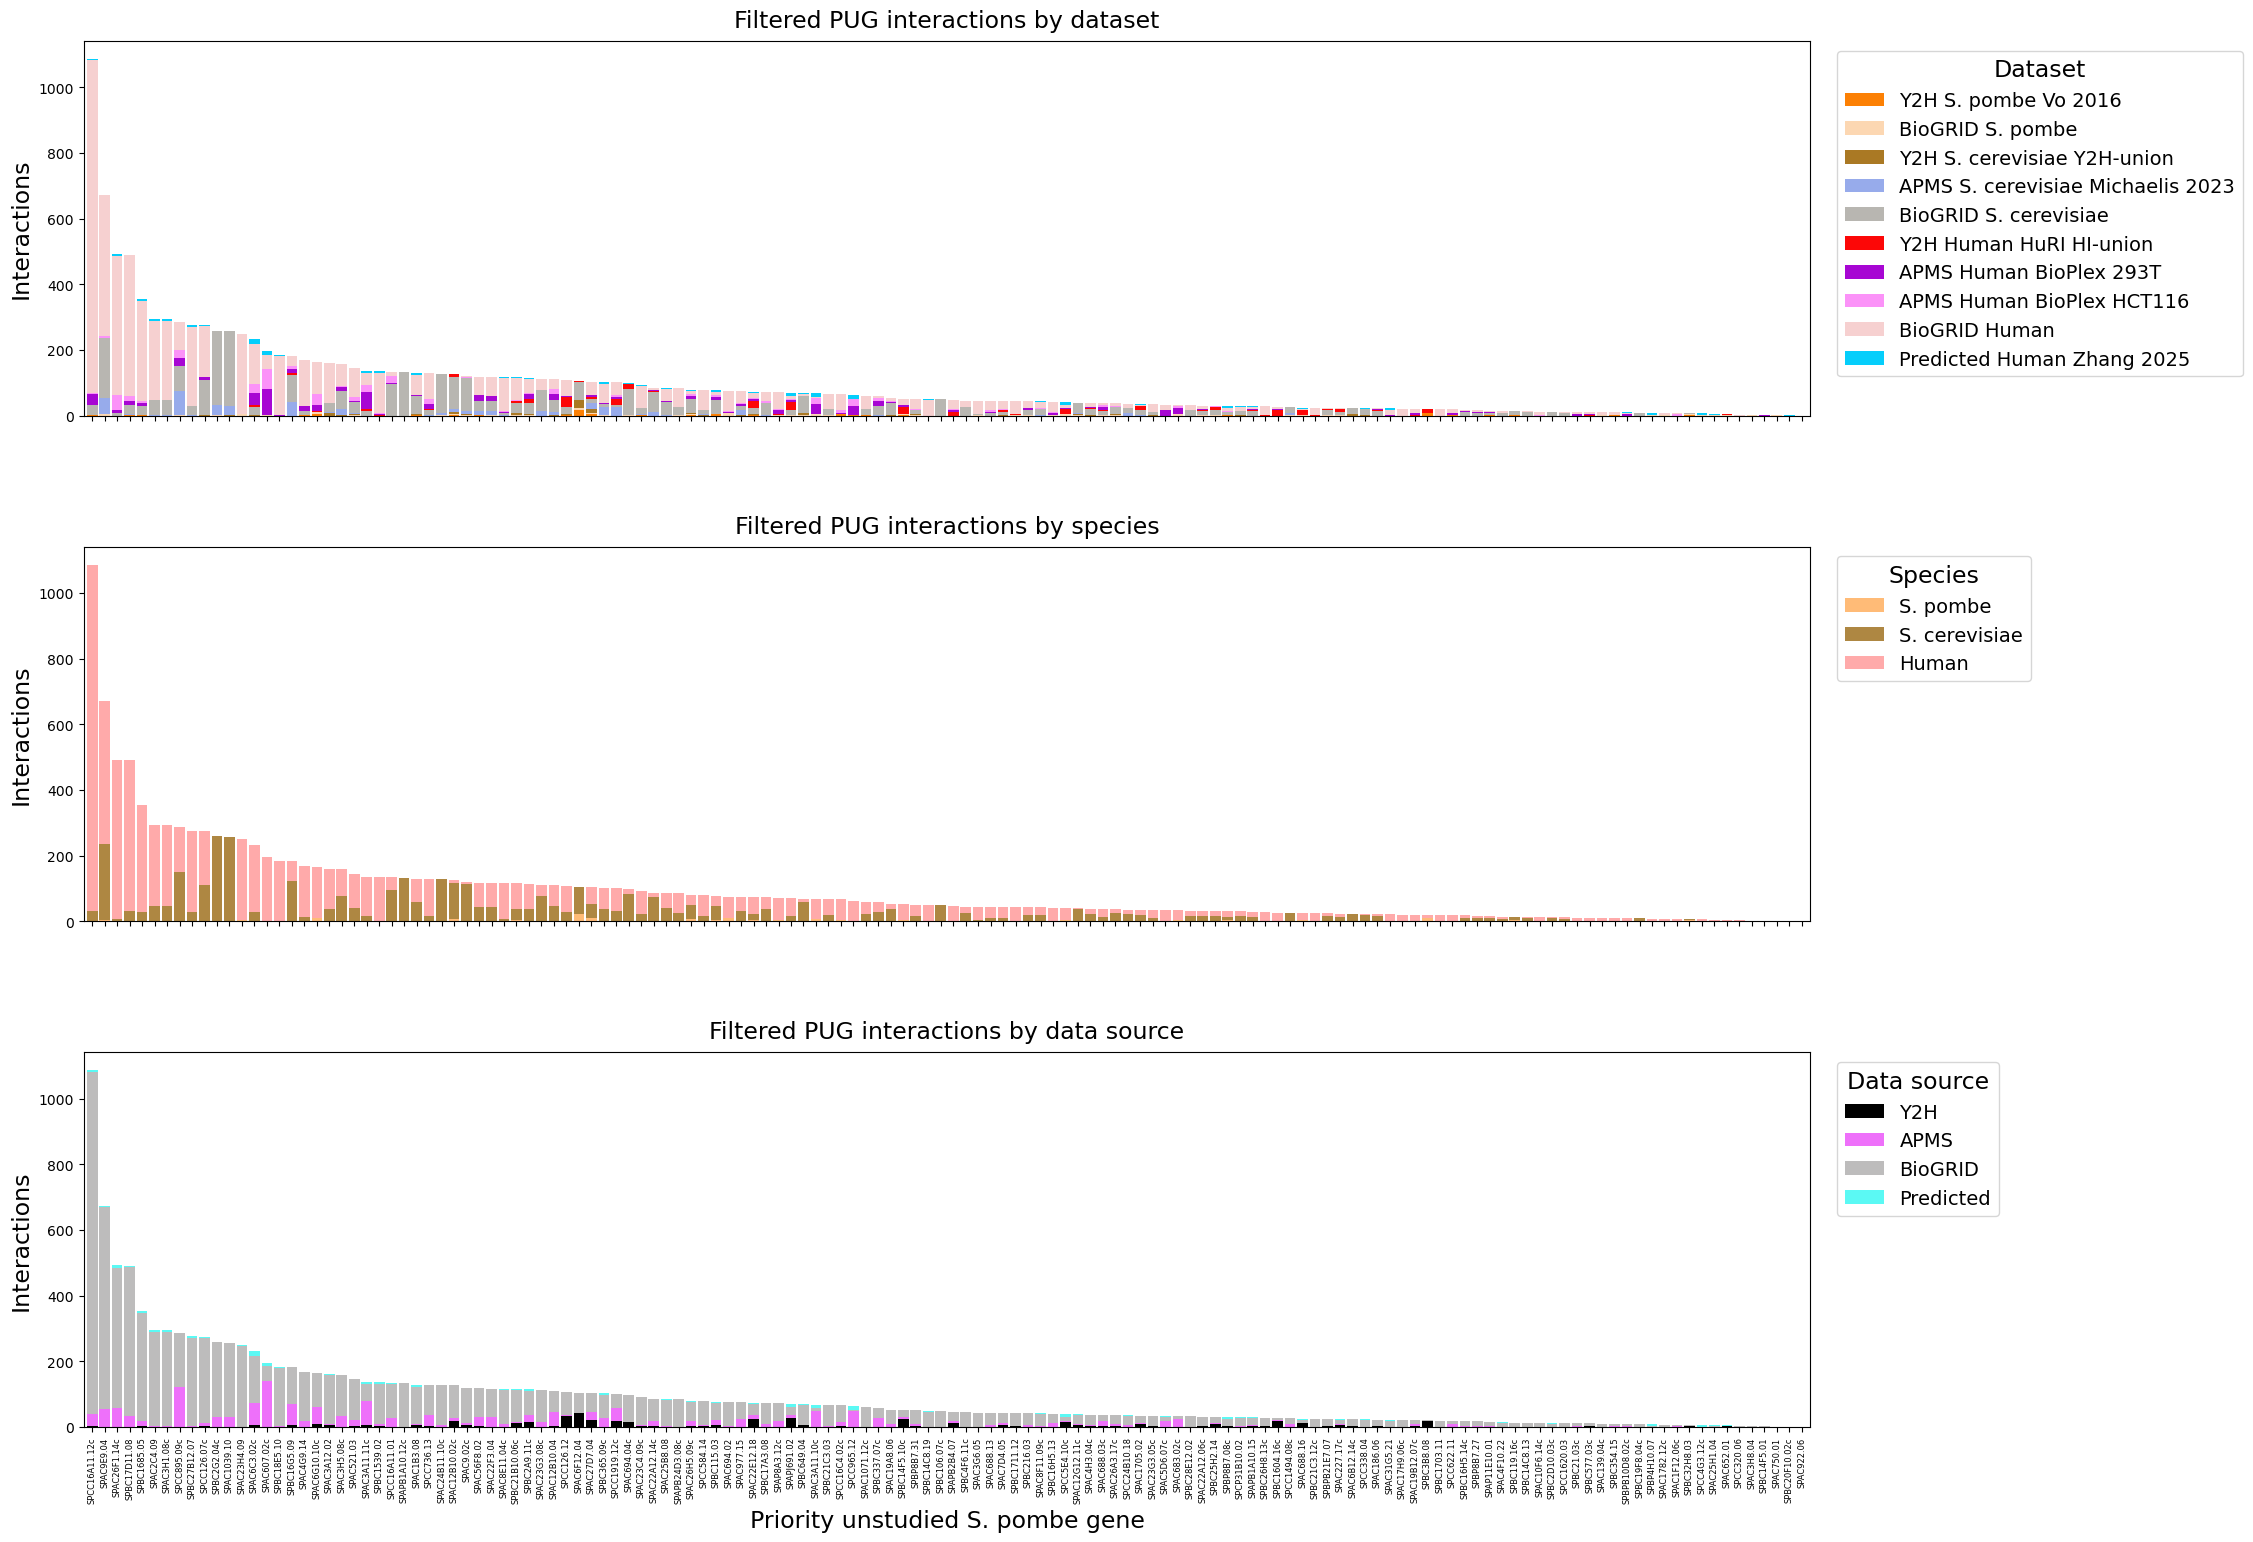

,gene_category,Y2H S. pombe Vo 2016,BioGRID S. pombe,Y2H S. cerevisiae Y2H-union,APMS S. cerevisiae Michaelis 2023,BioGRID S. cerevisiae,Y2H Human HuRI HI-union,APMS Human BioPlex 293T,APMS Human BioPlex HCT116,BioGRID Human,Predicted Human Zhang 2025,total_interactions
gene_systematic_id,,,,,,,,,,,,
SPCC16A11.12c,Priority Unstudied,1,0,0,1,29,1,35,1,1014,5,1087
SPAC9E9.04,Priority Unstudied,0,4,0,49,182,0,2,4,430,1,672
SPAC26F1.14c,Priority Unstudied,0,0,0,0,7,0,10,47,421,7,492
SPBC17D11.08,Priority Unstudied,1,1,0,4,26,0,12,17,427,2,490
SPBC1685.05,Priority Unstudied,2,0,0,1,25,0,10,5,305,6,354
...,...,...,...,...,...,...,...,...,...,...,...,...
SPAC3H8.04,Priority Unstudied,0,1,0,0,0,1,0,0,0,0,2
SPBC14F5.01,Priority Unstudied,0,0,0,0,0,0,1,0,1,0,2
SPAC750.01,Priority Unstudied,0,1,0,0,0,0,0,0,0,0,1


In [143]:
category_colors = {
    "Studied": "#1f77b4",
    "Non-Priority Unstudied": "#ff7f0e",
    "Priority Unstudied": "#2ca02c",
}

dataset_order = list(dataset_categories)
missing_dataset_columns = set(dataset_order) - set(source_counts_pivot_df.columns)
if missing_dataset_columns:
    raise KeyError(f"Dataset columns are missing from source_counts_pivot_df: {sorted(missing_dataset_columns)}")

pug_source_counts_pivot_df = source_counts_pivot_df.loc[
    source_counts_pivot_df["gene_category"] == "Priority Unstudied"
].copy()
pug_source_counts_pivot_df = pug_source_counts_pivot_df.sort_values(
    "total_interactions", ascending=False, kind="stable"
)
pug_dataset_counts_df = pug_source_counts_pivot_df[dataset_order]

species_datasets = {
    species: [
        dataset for dataset, (dataset_species, _) in dataset_categories.items()
        if dataset_species == species
    ]
    for species in species_colormap
}
data_source_datasets = {
    data_source: [
        dataset for dataset, (_, dataset_data_source) in dataset_categories.items()
        if dataset_data_source == data_source
    ]
    for data_source in data_source_colormap
}

pug_species_counts_pivot_df = pd.DataFrame(
    {
        species: pug_dataset_counts_df[species_datasets[species]].sum(axis=1)
        for species in species_colormap
    },
    index=pug_dataset_counts_df.index,
).reindex(columns=species_colormap.keys(), fill_value=0)
pug_data_source_counts_pivot_df = pd.DataFrame(
    {
        data_source: pug_dataset_counts_df[data_source_datasets[data_source]].sum(axis=1)
        for data_source in data_source_colormap
    },
    index=pug_dataset_counts_df.index,
).reindex(columns=data_source_colormap.keys(), fill_value=0)

expected_totals = pug_source_counts_pivot_df["total_interactions"].astype(int)
assert pug_species_counts_pivot_df.sum(axis=1).astype(int).equals(expected_totals)
assert pug_data_source_counts_pivot_df.sum(axis=1).astype(int).equals(expected_totals)

figure_width = max(14, len(pug_dataset_counts_df) * 0.18)
fig, axes = plt.subplots(3, 1, figsize=(figure_width, 18), sharex=True)
plot_specs = [
    (
        pug_dataset_counts_df,
        [dataset_colormap[dataset] for dataset in pug_dataset_counts_df.columns],
        "Dataset",
        "Filtered PUG interactions by dataset",
    ),
    (
        pug_species_counts_pivot_df,
        [species_colormap[species] for species in pug_species_counts_pivot_df.columns],
        "Species",
        "Filtered PUG interactions by species",
    ),
    (
        pug_data_source_counts_pivot_df,
        [data_source_colormap[source] for source in pug_data_source_counts_pivot_df.columns],
        "Data source",
        "Filtered PUG interactions by data source",
    ),
]

for ax, (plot_data, colors, legend_title, title) in zip(axes, plot_specs):
    plot_data.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=colors,
        width=0.85,
    )
    ax.set_ylabel("Interactions", fontsize=17)
    ax.set_title(title, fontsize=17, pad=10)
    ax.tick_params(axis="x", labelrotation=90, labelsize=6)
    ax.legend(
        title=legend_title,
        fontsize=14,
        title_fontsize=17,
        bbox_to_anchor=(1.01, 1),
        loc="upper left",
    )

axes[-1].set_xlabel("Priority unstudied S. pombe gene", fontsize=17)
fig.subplots_adjust(right=0.82, hspace=0.35)
fig.savefig(BASE_DIR / "ppis" / "pug_interactions_plot.svg")
plt.show()

pug_source_counts_pivot_df

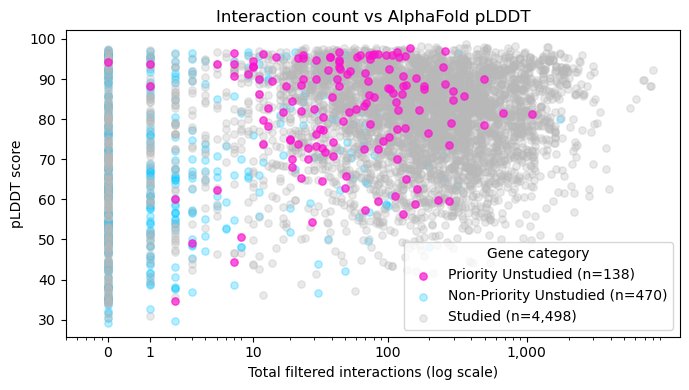

In [160]:
category_colors = {
    "Priority Unstudied": "#fa12cf",
    "Non-Priority Unstudied": "#0ec7ff",
    "Studied": "#b8b8b8",
}

category_alpha = {
    "Priority Unstudied": 0.7,
    "Non-Priority Unstudied": 0.3,
    "Studied": 0.3,
}

PLDDT_ANNOTATIONS_PATH = (
    BASE_DIR / "pombe_alphafold_structures" / "plddt_all_genes_pug_annotations.csv"
)
plddt_annotations_df = pd.read_csv(
    PLDDT_ANNOTATIONS_PATH,
    usecols=["gene_systematic_id", "gene_category", "plddt_score"],
)
plddt_annotations_df["plddt_score"] = pd.to_numeric(
    plddt_annotations_df["plddt_score"], errors="coerce"
)

interaction_gene_df = (
    source_counts_pivot_df[["gene_category", "total_interactions"]]
    .rename(columns={"gene_category": "gene_category_source"})
    .reset_index()
)
interaction_plddt_df = interaction_gene_df.merge(
    plddt_annotations_df.rename(columns={"gene_category": "gene_category_annotation"}),
    on="gene_systematic_id",
    how="left",
    validate="one_to_one",
)

category_comparison = interaction_plddt_df.dropna(
    subset=["gene_category_source", "gene_category_annotation"]
)
category_mismatches = category_comparison.loc[
    category_comparison["gene_category_source"]
    != category_comparison["gene_category_annotation"]
]
if not category_mismatches.empty:
    raise ValueError(
        "Gene category annotations disagree between source_counts_pivot_df and "
        "the pLDDT annotation file:\n"
        + category_mismatches[
            ["gene_systematic_id", "gene_category_source", "gene_category_annotation"]
        ].to_string(index=False)
    )

interaction_plddt_df["gene_category"] = interaction_plddt_df["gene_category_source"]
interaction_plddt_df = interaction_plddt_df.dropna(
    subset=["plddt_score", "gene_category"]
)

unmapped_categories = set(interaction_plddt_df["gene_category"]) - set(category_colors)
if unmapped_categories:
    raise KeyError(f"No plot color defined for gene categories: {sorted(unmapped_categories)}")

max_interactions = int(interaction_plddt_df["total_interactions"].max())
tick_counts = [0]
if max_interactions > 0:
    tick_counts.extend(
        10 ** power
        for power in range(int(np.floor(np.log10(max_interactions))) + 1)
    )

fig, ax = plt.subplots(figsize=(7, 4))

plot_order = [
    category
    for category in category_colors
    if category != "Priority Unstudied"
] + ["Priority Unstudied"]

for category in plot_order:
    category_df = interaction_plddt_df[
        interaction_plddt_df["gene_category"] == category
    ]
    ax.scatter(
        category_df["total_interactions"] + 1,
        category_df["plddt_score"],
        color=category_colors[category],
        alpha=category_alpha[category],
        s=28,
        zorder=3 if category == "Priority Unstudied" else 2,
        label=f"{category} (n={len(category_df):,})",
    )

handles, labels = ax.get_legend_handles_labels()
priority_index = next(
    i for i, label in enumerate(labels)
    if label.startswith("Priority Unstudied")
)
legend_order = [priority_index] + [
    i for i in range(len(labels)) if i != priority_index
]
ax.legend(
    [handles[i] for i in legend_order],
    [labels[i] for i in legend_order],
    title="Gene category",
)


ax.set_xscale("log")
ax.set_xticks([count + 1 for count in tick_counts])
ax.set_xticklabels([f"{count:,}" for count in tick_counts])
ax.set_xlim(left=0.5)
ax.set_xlabel("Total filtered interactions (log scale)")
ax.set_ylabel("pLDDT score")
ax.set_title("Interaction count vs AlphaFold pLDDT")
plt.tight_layout()
plt.show()
fig.savefig(BASE_DIR / "ppis" / "interaction_count_vs_alphafold_plddt.svg")

In [ ]:
#Genes with fewer than 10 total interactions.  Might be good candidates for targeted study. 

for item in pug_source_counts_pivot_df.loc[pug_source_counts_pivot_df['total_interactions']<10].index:
    print(item)

SPBC19F8.04c
SPBP4H10.07
SPAC1782.12c
SPAC1F12.06c
SPBC32H8.03
SPCC4G3.12c
SPAC25H1.04
SPAC652.01
SPCC320.06
SPAC3H8.04
SPBC14F5.01
SPAC750.01
SPBC20F10.02c
SPAC922.06


# Merge datasets and see which interactions are supported by multiple datasets. 

In [168]:
pombe_dataset_specs = [
    (
        "Y2H S. pombe Vo 2016",
        BASE_DIR / "ppis" / "vo_pombe_y2h" / "vo_y2h_processed.csv",
        "sp_gene_1",
        "sp_gene_2",
    ),
    (
        "BioGRID S. pombe",
        BIOGRID_DIR / "biogrid_pombe_physical.csv",
        "sp_gene_1",
        "sp_gene_2",
    ),
]

mapped_dataset_specs = [
    (dataset_name, filepath, *source_id_columns[dataset_name])
    for _, _, dataset_name, _, filepath in mapped_datasets
]
dataset_specs = pombe_dataset_specs + mapped_dataset_specs

merged_columns = [
    "sp_gene_1",
    "sp_gene_2",
    "source_id_1",
    "source_id_2",
    "sp_gene_1_unknown",
    "sp_gene_1_PUG",
    "sp_gene_2_unknown",
    "sp_gene_2_PUG",
    "dataset",
]
linked_column_pairs = [
    ("source_id_1", "source_id_2"),
    ("sp_gene_1_unknown", "sp_gene_2_unknown"),
    ("sp_gene_1_PUG", "sp_gene_2_PUG"),
]
merged_interaction_frames = []
dataset_row_counts = {}

for dataset_name, filepath, source_col_1, source_col_2 in dataset_specs:
    load_columns = list(dict.fromkeys([
        "sp_gene_1",
        "sp_gene_2",
        source_col_1,
        source_col_2,
    ]))
    dataset_df = pd.read_csv(filepath, usecols=load_columns, low_memory=False)

    interaction_df = pd.DataFrame({
        "sp_gene_1": dataset_df["sp_gene_1"],
        "sp_gene_2": dataset_df["sp_gene_2"],
        "source_id_1": dataset_df[source_col_1],
        "source_id_2": dataset_df[source_col_2],
    })
    interaction_df = ugt.annotate_unknown_and_pug(
        interaction_df, "sp_gene_1", unknown_df
    )
    interaction_df = ugt.annotate_unknown_and_pug(
        interaction_df, "sp_gene_2", unknown_df
    )
    interaction_df = ugt.sort_gene_pair_columns(
        interaction_df,
        "sp_gene_1",
        "sp_gene_2",
        linked_column_pairs=linked_column_pairs,
    )
    interaction_df = interaction_df.dropna(
        subset=["sp_gene_1", "sp_gene_2"]
    ).copy()
    interaction_df["dataset"] = dataset_name
    interaction_df = interaction_df[merged_columns]

    dataset_row_counts[dataset_name] = len(interaction_df)
    merged_interaction_frames.append(interaction_df)
    print(f"{dataset_name}: {len(interaction_df):,} interactions with two S. pombe orthologs")

ppis_merged_df = pd.concat(merged_interaction_frames, ignore_index=True)
assert ppis_merged_df[["sp_gene_1", "sp_gene_2"]].notna().all().all()
assert ppis_merged_df.columns.tolist() == merged_columns
assert set(ppis_merged_df["dataset"].unique()) == set(dataset_categories)

PPIS_MERGED_PATH = BASE_DIR / "ppis" / "ppis_merged.csv"
ppis_merged_df.to_csv(PPIS_MERGED_PATH, index=False)
print(f"Saved {len(ppis_merged_df):,} rows to {PPIS_MERGED_PATH}")
ppis_merged_df.head()

Y2H S. pombe Vo 2016: 2,278 interactions with two S. pombe orthologs
BioGRID S. pombe: 19,176 interactions with two S. pombe orthologs
Y2H S. cerevisiae Y2H-union: 4,117 interactions with two S. pombe orthologs
APMS S. cerevisiae Michaelis 2023: 40,524 interactions with two S. pombe orthologs
BioGRID S. cerevisiae: 302,592 interactions with two S. pombe orthologs
Y2H Human HuRI HI-union: 5,223 interactions with two S. pombe orthologs
APMS Human BioPlex HCT116: 17,024 interactions with two S. pombe orthologs
APMS Human BioPlex 293T: 24,946 interactions with two S. pombe orthologs
BioGRID Human: 333,009 interactions with two S. pombe orthologs
Predicted Human Zhang 2025: 10,856 interactions with two S. pombe orthologs
Saved 759,745 rows to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppis_merged.csv


,sp_gene_1,sp_gene_2,source_id_1,source_id_2,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG,dataset
0,SPAC1002.03c,SPAC14C4.05c,SPAC1002.03c,SPAC14C4.05c,False,False,False,False,Y2H S. pombe Vo 2016
1,SPAC1002.05c,SPAC821.07c,SPAC1002.05c,SPAC821.07c,False,False,False,False,Y2H S. pombe Vo 2016
2,SPAC1002.07c,SPAC1002.07c,SPAC1002.07c,SPAC1002.07c,False,False,False,False,Y2H S. pombe Vo 2016
3,SPAC1002.07c,SPBC887.08,SPAC1002.07c,SPBC887.08,False,False,True,False,Y2H S. pombe Vo 2016
4,SPAC1002.14,SPBC23G7.08c,SPAC1002.14,SPBC23G7.08c,False,False,False,False,Y2H S. pombe Vo 2016


In [ ]:
# Confirm Cell 55 kept each interaction in a consistent alphabetic orientation.
assert (ppis_merged_df["sp_gene_1"] <= ppis_merged_df["sp_gene_2"]).all()

interaction_identity_columns = [
    "sp_gene_1",
    "sp_gene_2",
    "sp_gene_1_unknown",
    "sp_gene_1_PUG",
    "sp_gene_2_unknown",
    "sp_gene_2_PUG",
]
within_dataset_group_columns = interaction_identity_columns + ["dataset"]

# Count source records for each interaction within each dataset. Repeated rows
# are retained as detections, including multiple records from the same source.
ppis_merged_deduplicated_within_dataset_df = (
    ppis_merged_df
    .groupby(within_dataset_group_columns, dropna=False)
    .size()
    .reset_index(name="n_detections")
)

within_dataset_path = (
    BASE_DIR / "ppis" / "ppis_merged_deduplicated_within_dataset.csv"
)
ppis_merged_deduplicated_within_dataset_df.to_csv(
    within_dataset_path, index=False
)

# Combine per-dataset counts and keep the datasets that support each pair.
ppis_merged_deduplicated_df = (
    ppis_merged_deduplicated_within_dataset_df
    .groupby(interaction_identity_columns, dropna=False)
    .agg(
        n_detections=("n_detections", "sum"),
        datasets=("dataset", lambda values: sorted(values.unique().tolist())),
    )
    .reset_index()
)

assert (
    ppis_merged_deduplicated_within_dataset_df["n_detections"].sum()
    == len(ppis_merged_df)
)
assert (
    ppis_merged_deduplicated_df["n_detections"].sum()
    == len(ppis_merged_df)
)

print(
    f"Saved {len(ppis_merged_deduplicated_within_dataset_df):,} "
    f"interaction-dataset rows to {within_dataset_path}"
)
print(
    f"Summarized {len(ppis_merged_deduplicated_df):,} unique interactions "
    f"across {ppis_merged_df['dataset'].nunique()} datasets"
)
ppis_merged_deduplicated_df.head()

ppis_merged_deduplicated_df.to_csv(
    BASE_DIR / "ppis" / "ppis_merged_deduplicated.csv", index=False
)

Saved 475,534 interaction-dataset rows to G:\My Drive\Crick_LMS\projects\a_unstudied_genes\ppis\ppis_merged_deduplicated_within_dataset.csv
Summarized 396,727 unique interactions across 10 datasets


,sp_gene_1,sp_gene_2,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG,n_detections,datasets
0,SPAC1002.01,SPBC16E9.13,False,False,False,False,1,[BioGRID S. cerevisiae]
1,SPAC1002.01,SPBC1709.05,False,False,False,False,1,[BioGRID S. cerevisiae]
2,SPAC1002.02,SPAC12B10.02c,False,False,True,True,1,[BioGRID S. cerevisiae]
3,SPAC1002.02,SPAC13G7.02c,False,False,False,False,3,[BioGRID S. cerevisiae]
4,SPAC1002.02,SPAC1486.05,False,False,False,False,1,[APMS S. cerevisiae Michaelis 2023]


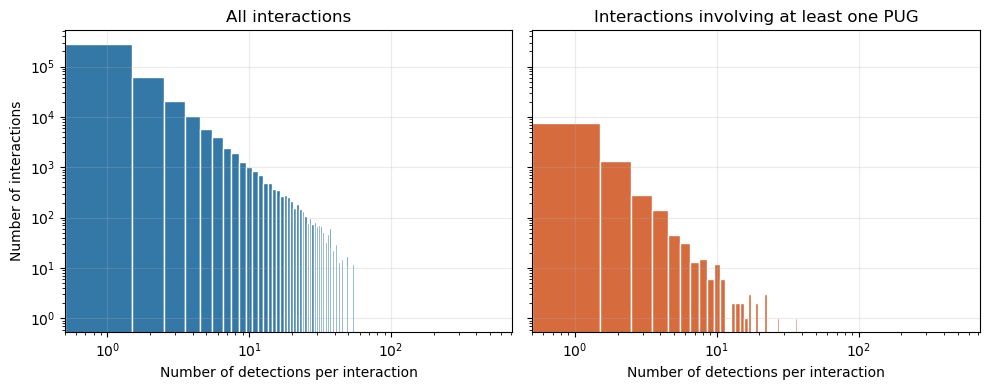

In [6]:
ppis_merged_deduplicated_df = pd.read_csv(BASE_DIR / "ppis" / "ppis_merged_deduplicated.csv")

pug_interactions_mask = (
    ppis_merged_deduplicated_df["sp_gene_1_PUG"]
    | ppis_merged_deduplicated_df["sp_gene_2_PUG"]
).fillna(False)
pug_interactions_deduplicated_df = ppis_merged_deduplicated_df.loc[
    pug_interactions_mask
]

max_detections = int(ppis_merged_deduplicated_df["n_detections"].max())
detection_bins = np.arange(0.5, max_detections + 1.5, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
plot_specs = [
    (
        ppis_merged_deduplicated_df["n_detections"],
        "All interactions",
        "#3478a8",
    ),
    (
        pug_interactions_deduplicated_df["n_detections"],
        "Interactions involving at least one PUG",
        "#d66b3d",
    ),
]

for ax, (detection_counts, title, color) in zip(axes, plot_specs):
    ax.hist(detection_counts, bins=detection_bins, color=color, edgecolor="white")
    ax.set_title(title)
    ax.set_xscale("log")
    ax.set_xlim(0.5, max_detections + 0.5)
    ax.set_xlabel("Number of detections per interaction")
    ax.set_yscale("log")
    ax.grid(axis="both", which="major", alpha=0.25)

axes[0].set_ylabel("Number of interactions")
fig.tight_layout()
plt.show()
fig.savefig(BASE_DIR / "ppis" / "ppis_merged_deduplicated_histogram.svg")

# Compare AP/MS data against predicted interactions

23 public partners, 23 with UniProt IDs; unmapped: []
in_public_db
False    2635
True       18
Name: count, dtype: int64
5 public partners missing from AP/MS data: ['num1', 'oca2', 'pef1', 'pfd5', 'ppk8']


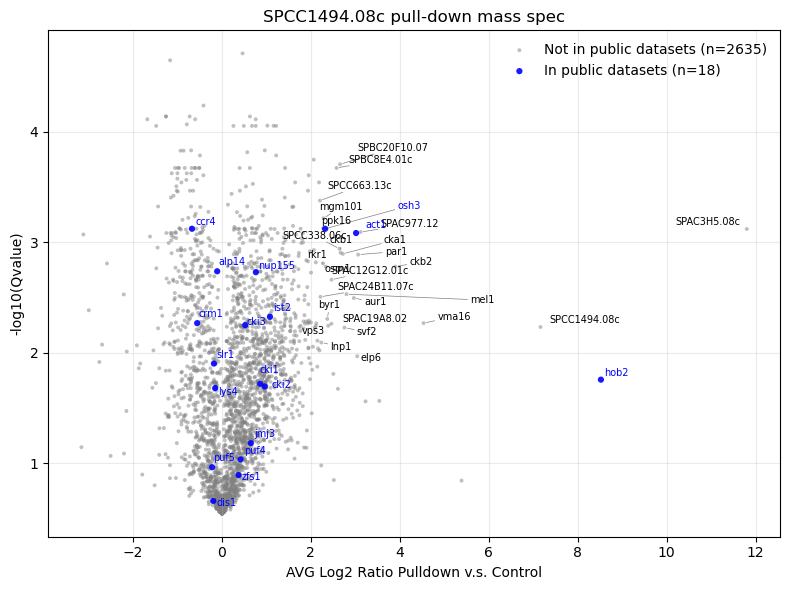

In [18]:
# Volcano plot of the pull-down mass-spec data for SPCC1494.08c (Spectronaut-style candidates table).
# Note: the "AVG Log2 Ratio" / "Qvalue" columns are in the candidates file, not the Report.tsv in the same folder.
MS_DIR = BASE_DIR / "geneD_Shaimaa"
ms_candidates_df = pd.read_csv(MS_DIR / "20260820004455_candidates.tsv", sep="\t")

# Ratio is c / d; multiplying by -1 puts d-enriched proteins on the right
ms_candidates_df["neg_log2_ratio"] = -1 * ms_candidates_df["AVG Log2 Ratio"]
ms_candidates_df["neg_log10_qvalue"] = -np.log10(ms_candidates_df["Qvalue"])

# Public interactions for the bait (sp_gene_1 / sp_gene_2 are S. pombe systematic IDs)
BAIT_GENE = "SPCC1494.08c"
public_ppi_df = pd.read_csv(BASE_DIR / "ppis" / "specific_gene_overviews" / "SPCC1494_08C" / "SPCC1494_08c_interactions_filtered.csv")

# Partner gene of the bait in each public interaction, mapped to UniProt IDs
public_partners = public_ppi_df["sp_gene_1"].where(public_ppi_df["sp_gene_1"] != BAIT_GENE, public_ppi_df["sp_gene_2"])
public_partner_uniprot = {ugt.GENE_ID_TO_UNIPROT_ID.get(g) for g in public_partners} - {None}
unmapped = sorted(set(public_partners) - set(ugt.GENE_ID_TO_UNIPROT_ID))
print(f"{len(public_partners.unique())} public partners, {len(public_partner_uniprot)} with UniProt IDs; unmapped: {unmapped}")

# UniProtIds can hold several protein-group members separated by ';'; match if any is a public partner
ms_candidates_df["in_public_db"] = ms_candidates_df["UniProtIds"].apply(
    lambda ids: any(i in public_partner_uniprot for i in str(ids).split(";")))
print(ms_candidates_df["in_public_db"].value_counts())

from adjustText import adjust_text

# Display name for a systematic ID: gene name if available, otherwise the systematic ID itself
def display_name(gene_id):
    name = ugt.GENE_ID_TO_NAME.get(gene_id)
    return name if isinstance(name, str) and name else gene_id

# Public partners absent from the AP/MS data (no UniProt ID in any protein group)
ms_uniprot_ids = {i for ids in ms_candidates_df["UniProtIds"].astype(str) for i in ids.split(";")}
missing_partners = sorted(
    display_name(g) for g in set(public_partners)
    if ugt.GENE_ID_TO_UNIPROT_ID.get(g) not in ms_uniprot_ids)
print(f"{len(missing_partners)} public partners missing from AP/MS data: {missing_partners}")

# Label for each AP/MS row: for public partners use the GENE_ID_TO_NAME name; otherwise the 'Genes' column
uniprot_to_public_name = {ugt.GENE_ID_TO_UNIPROT_ID[g]: display_name(g) for g in set(public_partners) if g in ugt.GENE_ID_TO_UNIPROT_ID}
def row_label(row):
    for i in str(row["UniProtIds"]).split(";"):
        if i in uniprot_to_public_name:
            return uniprot_to_public_name[i]
    return str(row["Genes"]).split(";")[0]
ms_candidates_df["label"] = ms_candidates_df.apply(row_label, axis=1)

# Label public partners, plus any protein with x > 2.2 and y > 1.9
X_CUTOFF, Y_CUTOFF = 2.2, 1.9
to_label = ms_candidates_df[ms_candidates_df["in_public_db"] |
                            ((ms_candidates_df["neg_log2_ratio"] > X_CUTOFF) & (ms_candidates_df["neg_log10_qvalue"] > Y_CUTOFF))]

fig, ax = plt.subplots(figsize=(8, 6))
for in_db, color, label, zorder in [(False, "grey", "Not in public datasets", 1), (True, "blue", "In public datasets", 2)]:
    subset = ms_candidates_df[ms_candidates_df["in_public_db"] == in_db]
    ax.scatter(subset["neg_log2_ratio"], subset["neg_log10_qvalue"], s=8 if not in_db else 20,
               alpha=0.5 if not in_db else 0.9, color=color, edgecolor="none", label=f"{label} (n={len(subset)})", zorder=zorder)
# Place labels with adjustText so they don't overlap each other or the points; thin arrows link label to point
texts = [ax.text(row["neg_log2_ratio"], row["neg_log10_qvalue"], row["label"], fontsize=7,
                 color="blue" if row["in_public_db"] else "black", zorder=3)
         for _, row in to_label.iterrows()]
adjust_text(texts, x=to_label["neg_log2_ratio"].values, y=to_label["neg_log10_qvalue"].values, ax=ax,
            arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
ax.legend(frameon=False)
ax.set_xlabel("AVG Log2 Ratio Pulldown v.s. Control")
ax.set_ylabel("-log10(Qvalue)")
ax.set_title("SPCC1494.08c pull-down mass spec")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


## Merge S. pombe and S. cerevisiae ortholog-derived datasets

Combine `pombe_ppi_overlap_df` with the S. cerevisiae ortholog-derived
interactions (restricted to pairs with two S. pombe orthologs), then
visualize dataset overlap with an UpSet plot.

In [146]:
# Restrict to interactions with a S. pombe ortholog on both sides, so the pair
# can be merged with pombe_ppi_overlap_df on (sp_gene_1, sp_gene_2)
cerev_ppi_both_orthologs_df = cerev_ppi_overlap_df[
    cerev_ppi_overlap_df["sp_gene_1"].notna() & cerev_ppi_overlap_df["sp_gene_2"].notna()
].copy()

# Sorting always places a lone NA in sp_gene_2, so sp_gene_1 should never be empty
assert cerev_ppi_both_orthologs_df["sp_gene_1"].notna().all(), "Empty sp_gene_1.  Sorting may not be working"

print(cerev_ppi_both_orthologs_df.shape)

# Both overlap tables have a "biogrid_physical" column; rename before merging so
# the S. pombe and S. cerevisiae-ortholog BIOGRID counts stay distinct
all_ppi_overlap_df = pombe_ppi_overlap_df[
    ["sp_gene_1", "sp_gene_2", "vo_et_al_2016", "biogrid_physical"]
].rename(columns={"biogrid_physical": "biogrid_physical_pombe"}).merge(
    cerev_ppi_both_orthologs_df[
        ["sp_gene_1", "sp_gene_2", "lambourne_interactions", "michaelis_interaction", "biogrid_physical"]
    ].rename(columns={"biogrid_physical": "biogrid_physical_cerev"}),
    on=["sp_gene_1", "sp_gene_2"], how="outer",
)

all_ppi_overlap_df["vo_et_al_2016"] = all_ppi_overlap_df["vo_et_al_2016"].fillna(False)
all_ppi_overlap_df["biogrid_physical_pombe"] = all_ppi_overlap_df["biogrid_physical_pombe"].fillna(0)
all_ppi_overlap_df["lambourne_interactions"] = all_ppi_overlap_df["lambourne_interactions"].fillna(0)
all_ppi_overlap_df["michaelis_interaction"] = all_ppi_overlap_df["michaelis_interaction"].fillna(False)
all_ppi_overlap_df["biogrid_physical_cerev"] = all_ppi_overlap_df["biogrid_physical_cerev"].fillna(0)

# Convert the non-boolean count columns to booleans (present if count > 0)
all_ppi_overlap_df["biogrid_pombe"] = all_ppi_overlap_df["biogrid_physical_pombe"] > 0
all_ppi_overlap_df["lambourne_y2h"] = all_ppi_overlap_df["lambourne_interactions"] > 0
all_ppi_overlap_df["biogrid_cerev_ortholog"] = all_ppi_overlap_df["biogrid_physical_cerev"] > 0

# Annotate PUG status of each gene in the pair, to allow filtering below
all_ppi_overlap_df = ugt.annotate_unknown_and_pug(all_ppi_overlap_df, "sp_gene_1", unknown_df)
all_ppi_overlap_df = ugt.annotate_unknown_and_pug(all_ppi_overlap_df, "sp_gene_2", unknown_df)

print(all_ppi_overlap_df.shape)
all_ppi_overlap_df.to_csv(BASE_DIR / "ppis" / "all_ppi_overlap_pombe_and_cerev_orthologs.csv", index=False)

all_ppi_overlap_df.head(10)

(242631, 11)
(253600, 14)


,sp_gene_1,sp_gene_2,vo_et_al_2016,biogrid_physical_pombe,lambourne_interactions,michaelis_interaction,biogrid_physical_cerev,biogrid_pombe,lambourne_y2h,biogrid_cerev_ortholog,sp_gene_1_unknown,sp_gene_1_PUG,sp_gene_2_unknown,sp_gene_2_PUG
0,SPAC1002.02,SPAC1786.03,False,1.0,0.0,True,3.0,True,False,True,False,False,False,False
1,SPAC1002.02,SPAC18G6.10,False,1.0,0.0,False,0.0,True,False,False,False,False,False,False
2,SPAC1002.02,SPCC737.03c,False,1.0,0.0,False,0.0,True,False,False,False,False,False,False
3,SPAC1002.03c,SPAC14C4.05c,True,0.0,0.0,False,0.0,False,False,False,False,False,False,False
4,SPAC1002.04c,SPAC23G3.09,False,1.0,0.0,True,6.0,True,False,True,False,False,False,False
5,SPAC1002.04c,SPAC631.02,False,1.0,0.0,False,0.0,True,False,False,False,False,False,False
6,SPAC1002.05c,SPAC821.07c,True,0.0,0.0,False,0.0,False,False,False,False,False,False,False
7,SPAC1002.05c,SPBC1718.07c,False,1.0,0.0,False,0.0,True,False,False,False,False,False,False
8,SPAC1002.06c,SPAC6G9.13c,False,7.0,0.0,False,0.0,True,False,False,False,False,False,False
9,SPAC1002.06c,SPBC1778.02,False,5.0,0.0,False,0.0,True,False,False,False,False,False,False


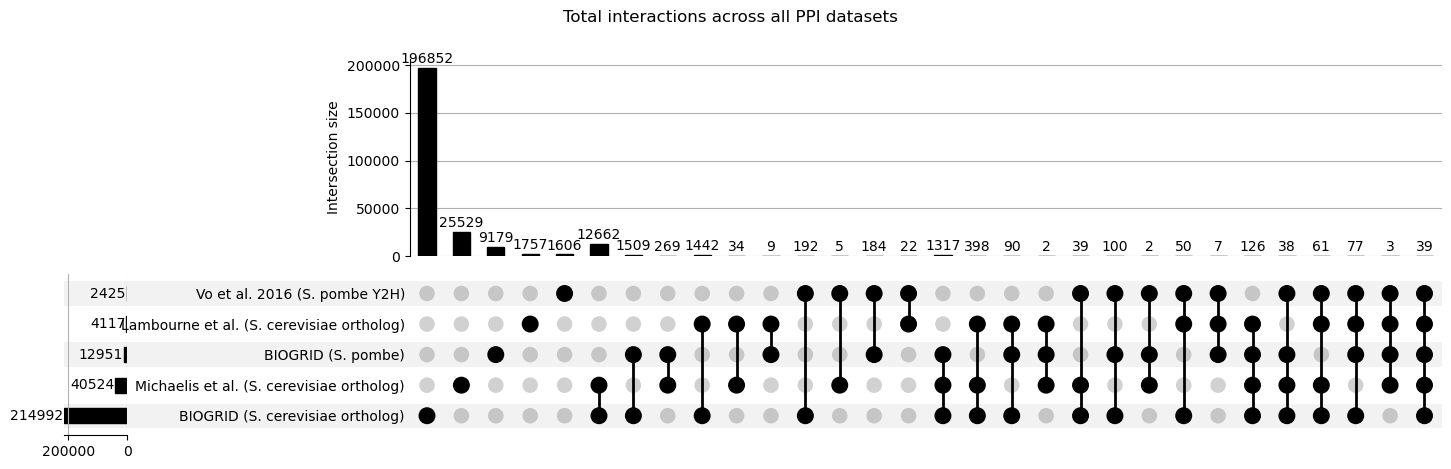

In [ ]:


# Label columns for the plot legend/axis
indicator_labels = {
    "vo_et_al_2016": "Vo et al. 2016 (S. pombe Y2H)",
    "biogrid_pombe": "BIOGRID (S. pombe)",
    "lambourne_y2h": "Lambourne et al. (S. cerevisiae ortholog)",
    "michaelis_interaction": "Michaelis et al. (S. cerevisiae ortholog)",
    "biogrid_cerev_ortholog": "BIOGRID (S. cerevisiae ortholog)",
}
upset_source_df = all_ppi_overlap_df.rename(columns=indicator_labels)

upset_data = upsetplot.from_indicators(list(indicator_labels.values()), data=upset_source_df)

UpSet(upset_data, subset_size="count", show_counts=True).plot()
plt.suptitle("Total interactions across all PPI datasets")
plt.show()

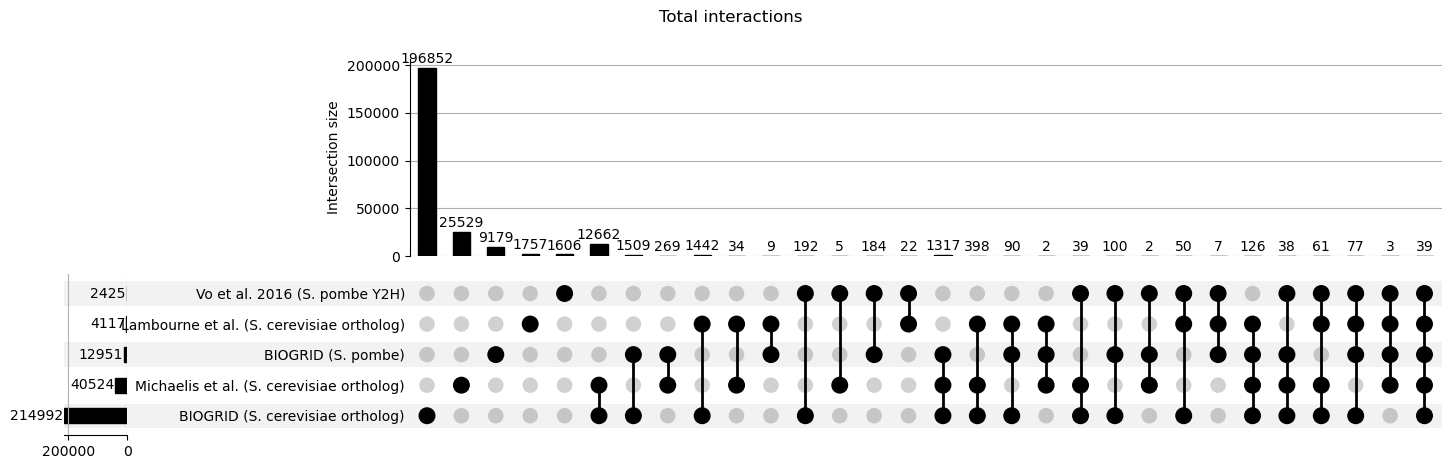

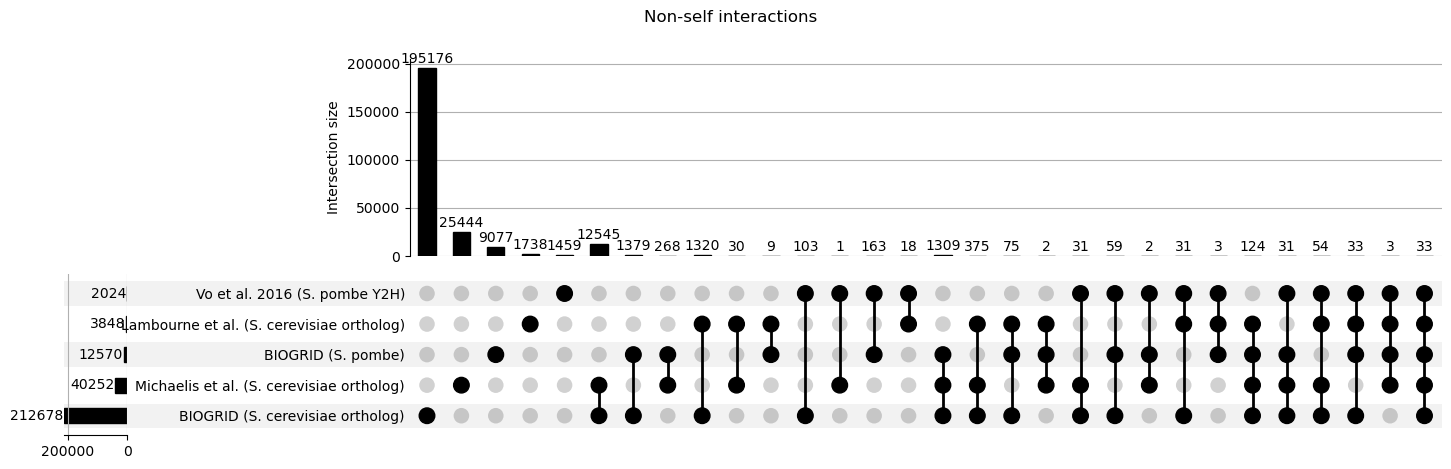

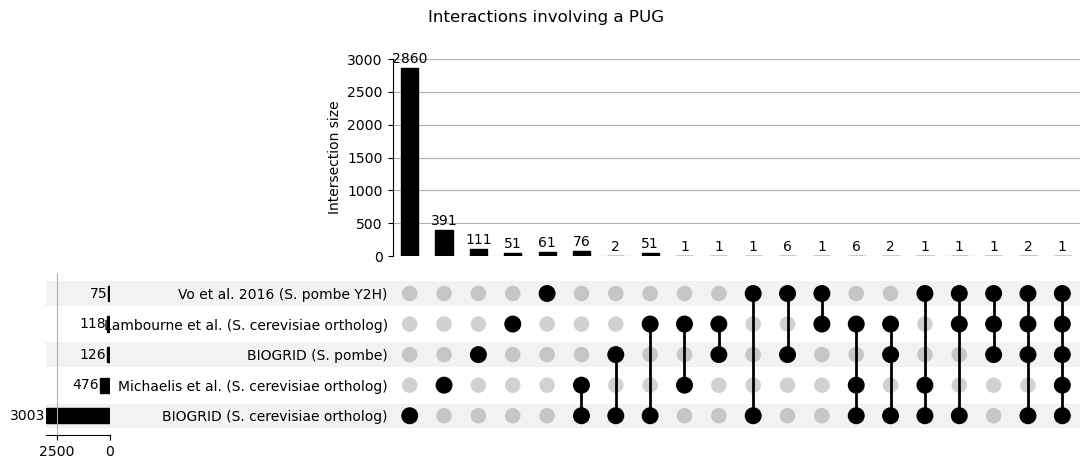

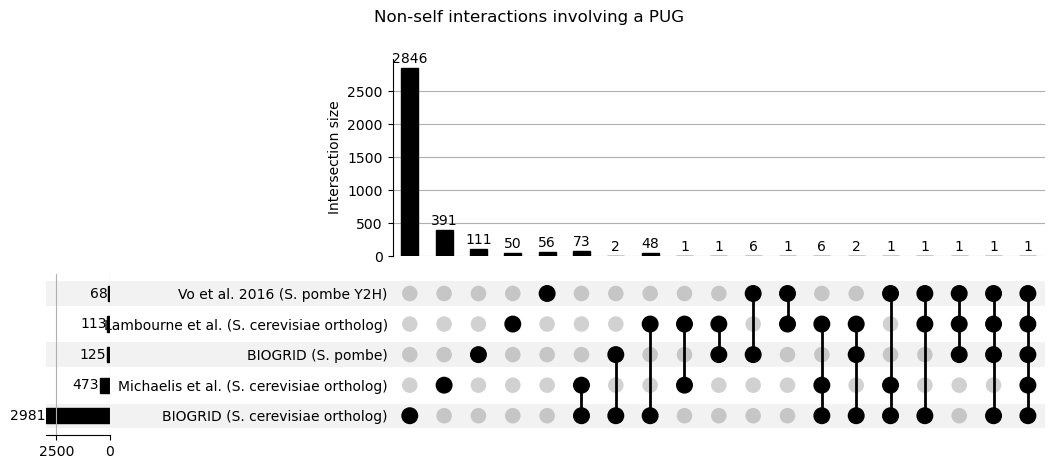

In [149]:
# Four vertically-stacked UpSet plots: total, non-self, PUG-involving, and
# non-self PUG-involving interactions (analogous to the Vo/BIOGRID Venn panels)
is_self = all_ppi_overlap_df["sp_gene_1"] == all_ppi_overlap_df["sp_gene_2"]
involves_pug = (
    all_ppi_overlap_df["sp_gene_1_PUG"].fillna(False).astype(bool)
    | all_ppi_overlap_df["sp_gene_2_PUG"].fillna(False).astype(bool)
)

upset_panels = [
    ("Total interactions", pd.Series(True, index=all_ppi_overlap_df.index)),
    ("Non-self interactions", ~is_self),
    ("Interactions involving a PUG", involves_pug),
    ("Non-self interactions involving a PUG", ~is_self & involves_pug),
]

# upsetplot's fig.plot() is incompatible with matplotlib SubFigures, so each
# panel gets its own figure; shown in sequence this still stacks vertically
for title, mask in upset_panels:
    panel_data = upsetplot.from_indicators(list(indicator_labels.values()), data=upset_source_df.loc[mask])
    fig = plt.figure(figsize=(10, 6))
    UpSet(panel_data, subset_size="count", show_counts=True).plot(fig=fig)
    fig.suptitle(title)
    plt.show()

In [151]:
# Interactions supported by 3 or more of the 5 datasets
dataset_indicator_cols = list(indicator_labels.keys())
support_count = all_ppi_overlap_df[dataset_indicator_cols].sum(axis=1)

well_supported_df = all_ppi_overlap_df.loc[
    (support_count >= 3) & ~is_self & involves_pug, ["sp_gene_1", "sp_gene_2"] + dataset_indicator_cols
].reset_index(drop=True)

well_supported_df = ugt.add_gene_name_column(well_supported_df, "sp_gene_1")
well_supported_df = ugt.add_gene_name_column(well_supported_df, "sp_gene_2")

print(well_supported_df.shape)
well_supported_df

(13, 9)


,sp_gene_1,sp_gene_1_name,sp_gene_2,sp_gene_2_name,vo_et_al_2016,biogrid_pombe,lambourne_y2h,michaelis_interaction,biogrid_cerev_ortholog
0,SPAC1B3.08,SPAC1B3.08,SPAC3G6.02,dss1,True,True,True,True,True
1,SPAC26A3.17c,rmt2,SPCC16C4.13c,rpl1201,False,True,True,False,True
2,SPAC26A3.17c,rmt2,SPCC16C4.13c,rpl1201,False,True,True,False,True
3,SPAC27D7.04,omt2,SPAC29B12.06c,rcd1,True,True,True,False,True
4,SPAC27D7.04,omt2,SPCC962.03c,cut15,True,True,True,False,False
5,SPAC6F12.04,tvp15,SPBC31F10.06c,sar1,True,False,True,False,True
6,SPAC823.03,ppk15,SPBC17D11.08,dca7,True,False,False,True,True
7,SPAC2G11.07c,ptc3,SPAC9.02c,SPAC9.02c,False,False,True,True,True
8,SPAC2G11.07c,ptc3,SPAC9.02c,SPAC9.02c,False,False,True,True,True
9,SPAC9.02c,SPAC9.02c,SPCC1223.11,ptc2,False,False,True,True,True



# Troubleshooting code for checking specific interactions in the Biogrid dataset

In [141]:
cerev_ppi_overlap_df[(cerev_ppi_overlap_df["sc_gene_1"]=="YAL005C") & (cerev_ppi_overlap_df["sc_gene_2"]=="YDR385W")]

,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,lambourne_interactions,michaelis_interaction,biogrid_physical
27236,SPAC13G7.02c,SPAC513.01c,YAL005C,YDR385W,0,True,3
27237,SPAC13G7.02c,SPCP31B10.07,YAL005C,YDR385W,0,True,3
27238,SPCC1739.13,SPAC513.01c,YAL005C,YDR385W,0,True,3
27239,SPCC1739.13,SPCP31B10.07,YAL005C,YDR385W,0,True,3


In [90]:
cerev_ppi_overlap_df[(cerev_ppi_overlap_df["sc_gene_2"]=="YAL005C") & (cerev_ppi_overlap_df["sc_gene_1"]=="YDR385W")]

,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,lambourne_interactions,michaelis_interaction,biogrid_physical
27241,SPAC513.01c,SPCC1739.13,YDR385W,YAL005C,0,True,3


In [88]:
cerev_to_pombe['YDR385W']

['SPAC513.01c', 'SPCP31B10.07']

In [89]:
cerev_to_pombe['YAL005C']

['SPAC13G7.02c', 'SPCC1739.13']

In [139]:
biogrid_cerevisiae_physical_df[(biogrid_cerevisiae_physical_df["sc_gene_1"]=="YAL005C") & (biogrid_cerevisiae_physical_df["sc_gene_2"]=="YDR385W")]["Publication Source"]

63011     PUBMED:19536198
127139    PUBMED:26217697
153435    PUBMED:25452130
229158    PUBMED:37968396
Name: Publication Source, dtype: object

In [134]:
biogrid_cerevisiae_physical_df[(biogrid_cerevisiae_physical_df["sc_gene_2"]=="YAL005C") & (biogrid_cerevisiae_physical_df["sc_gene_1"]=="YDR385W")]["Publication Source"]

63012    PUBMED:19536198
Name: Publication Source, dtype: object

In [ ]:
biogrid_cerevisiae_physical_filtered_df[(biogrid_cerevisiae_physical_filtered_df["sc_gene_name"]=="SPAC1002.03c") & (biogrid_pombe_physical_filtered_df["gene_2"]=="SPAC1002.04c")]



In [ ]:
biogrid_cerev_prep_df[(biogrid_cerev_prep_df["sc_gene_2"]=="YAL005C") & (biogrid_cerev_prep_df["sc_gene_1"]=="YDR385W")]

,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,Publication Source


In [138]:
biogrid_cerev_prep_df[(biogrid_cerev_prep_df["sc_gene_1"]=="YAL005C") & (biogrid_cerev_prep_df["sc_gene_2"]=="YDR385W")]

,sp_gene_1,sp_gene_2,sc_gene_1,sc_gene_2,Publication Source
85348,SPAC13G7.02c,SPAC513.01c,YAL005C,YDR385W,PUBMED:19536198
85349,SPAC13G7.02c,SPCP31B10.07,YAL005C,YDR385W,PUBMED:19536198
85350,SPCC1739.13,SPAC513.01c,YAL005C,YDR385W,PUBMED:19536198
85351,SPCC1739.13,SPCP31B10.07,YAL005C,YDR385W,PUBMED:19536198
85352,SPAC13G7.02c,SPAC513.01c,YAL005C,YDR385W,PUBMED:19536198
85353,SPCC1739.13,SPAC513.01c,YAL005C,YDR385W,PUBMED:19536198
85354,SPAC13G7.02c,SPCP31B10.07,YAL005C,YDR385W,PUBMED:19536198
85355,SPCC1739.13,SPCP31B10.07,YAL005C,YDR385W,PUBMED:19536198
179528,SPAC13G7.02c,SPAC513.01c,YAL005C,YDR385W,PUBMED:26217697
179529,SPAC13G7.02c,SPCP31B10.07,YAL005C,YDR385W,PUBMED:26217697
